# Phase 2.1 — Hybrid ช่วยรู้จำคำภาษามือจริงหรือไม่?

สมุดทดลองเดียวสำหรับข้อมูลจริง 6 คลิป: จากข้อมูล → pipeline → คะแนน → error analysis → รายงานที่ตรวจย้อนกลับได้

**คำถามวิจัย:** เมื่อคง encoder, tagger, bank และข้อมูล landmark เดิมไว้ การเพิ่มคะแนนกายภาพ 30% เปลี่ยนคำตอบตรงไหน และช่วยเมื่อเทียบเฉลยหรือไม่?

**สมมติฐานที่ทดสอบ:** คุณลักษณะหยาบอาจช่วยแยกคำที่รูปท่าต่างกัน แต่ coverage ต่ำและมือหายอาจทำให้ผลแย่ลง ต้องแสดงทั้งกรณีดีขึ้นและแย่ลง ไม่เลือกเฉพาะตัวอย่างที่สำเร็จ

**สถานะหลักฐาน:** ไม่ใส่ตัวเลขทดลองล่วงหน้า Output เกิดจากการรันจริงเท่านั้น ชื่อวิดีโอเป็นประโยคเฉลยตามผู้ใช้ยืนยัน แต่ยังไม่มีขอบเขตเวลารายคำ ไม่เปิด clip3 จากชุด held-out อื่น และไม่ใช้ 6 คลิปนี้ปรับน้ำหนัก

**วิธีใช้งาน:** เปิด Notebook นี้แล้ว Run All ด้วย kernel ที่มี pandas/matplotlib/pythainlp ส่วน inference เรียก `Boom/venv-sign2say/bin/python` โดยตรง ตรวจตาราง tokenization ก่อนใช้ WER อ้างอิงในรายงาน

## 1. Setup และตรวจ environment

ค้นหา repository จากตำแหน่ง Notebook โดยไล่ parent จึงไม่เกิด `Boom/.../Boom/...` ซ้ำ การ import โค้ดโมเดลและตรวจเวอร์ชันทำใน venv จริงก่อนเริ่ม inference


MediaPipe ใช้รุ่น 1.1.0 จาก `runtime_packages` เฉพาะการทดลองนี้ เพื่อแก้ native crash ของ 1.0.1. ไฟล์โมเดล `.task` เดิม และ environment Anaconda ไม่ถูกแก้; ตรวจเวอร์ชันที่แสดงด้านล่างก่อนรัน


In [1]:
from pathlib import Path
import sys, subprocess, importlib
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'modules/pipeline.py').is_file() and (p/'Boom').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('เปิด Notebook ภายใน DSI490-Sign2Say')
HERE = ROOT/'Boom/phase2.1/02_hybrid_score'
sys.path.insert(0, str(HERE))
import experiment_analysis as ex
importlib.reload(ex)
ex.setup()
ex.show_table(ex.environment(), '**ตรวจผล:** project_imports ต้องเป็น OK และ executable ต้องเป็น venv-sign2say; notebook_kernel อาจต่างได้ เพราะ subprocess ใช้ interpreter ที่กำหนดชัดเจน')

,component,value
0,python,"3.11.8 (main, Apr 19 2025, 22:30:49) [Clang 14.0.3 (clang-1403.0.22.14.1)]"
1,executable,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/Boom/venv-sign2say/bin/python
2,platform,macOS-26.2-arm64-arm-64bit
3,torch,2.14.1
4,onnxruntime,1.23.2
5,providers,"['CoreMLExecutionProvider', 'AzureExecutionProvider', 'CPUExecutionProvider']"
6,mediapipe,1.1.0
7,project_imports,OK
8,notebook_kernel,/Users/thawaphorn/anaconda3/bin/python


**ตรวจผล:** project_imports ต้องเป็น OK และ executable ต้องเป็น venv-sign2say; notebook_kernel อาจต่างได้ เพราะ subprocess ใช้ interpreter ที่กำหนดชัดเจน

### 1.1 ข้อมูลเข้าและที่มาของผล

คลิปจริงจาก `Boom/boom datatest` เท่านั้น ไม่มีการประกอบประโยคสังเคราะห์ในงานนี้ ความยาวและ FPS อ่านจากไฟล์จริง ข้อมูลจะถูกสกัดตาม pipeline ที่ 25 fps ไม่ใช่ frame index ดั้งเดิมของกล้อง

In [2]:
video_inventory = ex.inventory()
ex.show_table(video_inventory, '**อ่านตาราง:** duration_s เป็นเวลาคลิปต้นฉบับ; fps คืออัตราเฟรมวิดีโอ ไม่ใช่ fps inference')

,video,frames,fps,duration_s,width,height,MB
0,ฉันยังลืมคุณไม่ได้.MOV,366,29.837,12.267,540,960,3.524
1,ฉันแอบชอบคุณ.MOV,388,29.845,13.001,540,960,3.773
2,ตอนนี้กำลังเรียนภาษา.MOV,397,29.848,13.301,540,960,3.885
3,มีอะไรให้ฉันช่วยไหม.MOV,421,29.855,14.102,540,960,4.282
4,เราจะเป็นเพื่อนกันตลอดไป.MOV,450,29.863,15.069,540,960,4.408
5,เล่นเกมส์กันไหม.MOV,450,29.860,15.070,540,960,4.401


**อ่านตาราง:** duration_s เป็นเวลาคลิปต้นฉบับ; fps คืออัตราเฟรมวิดีโอ ไม่ใช่ fps inference

### 1.2 Ground truth จากชื่อไฟล์ที่ผู้ใช้ยืนยัน

`sentence_text` คือชื่อไฟล์ที่ตัดนามสกุลออกโดยตรง `glosses` เริ่มจาก newmm tokenization และแสดงให้ตรวจด้านล่าง การแบ่งหน่วยภาษาไทยไม่จำเป็นต้องเท่ากับหนึ่งท่าภาษามือ เช่น “ไม่ได้” อาจถูกแบ่งหลายหน่วย

แก้ `ground_truth.json` ได้: ปรับ `glosses` ให้เป็นหน่วยท่าที่ทำจริงและลำดับจริง แล้วตั้ง `gloss_order_verified=true` เมื่อดูวิดีโอยืนยัน ส่วน `segments` ใส่รายการ `{t0: วินาที, t1: วินาที, word: คำ}` สำหรับ Segment F1 และ Recall แบบจับคู่เวลา **ห้ามสร้างเวลาจากคำทำนายของโมเดลเป็นเฉลย**

In [3]:
import pandas as pd
annotation_path = ex.annotation_template()
annotations = ex.read(annotation_path)['videos']
ex.show_table(pd.DataFrame([dict(video=k, sentence=v.get('sentence_text'), reference_tokens=v.get('glosses'),
    order_verified=v.get('gloss_order_verified'), timed_labels=v.get('segments')) for k,v in annotations.items()]),
    '**อ่านตาราง:** ประโยคถูกยืนยันแล้ว แต่ tokens เป็นการแบ่งคำอัตโนมัติ ต้องตรวจหน่วยก่อนสรุป WER ระดับท่ามือ; timed_labels=None ทำให้ metric ที่ต้องใช้เวลาเป็น N/A')

,video,sentence,reference_tokens,order_verified,timed_labels
0,ฉันยังลืมคุณไม่ได้.MOV,ฉันยังลืมคุณไม่ได้,"[ฉัน, ยัง, ลืม, คุณ, ไม่, ได้]",False,None
1,ฉันแอบชอบคุณ.MOV,ฉันแอบชอบคุณ,"[ฉัน, แอบ, ชอบ, คุณ]",False,None
2,ตอนนี้กำลังเรียนภาษา.MOV,ตอนนี้กำลังเรียนภาษา,"[ตอนนี้, กำลัง, เรียน, ภาษา]",False,None
3,มีอะไรให้ฉันช่วยไหม.MOV,มีอะไรให้ฉันช่วยไหม,"[มี, อะไร, ให้, ฉัน, ช่วย, ไหม]",False,None
4,เราจะเป็นเพื่อนกันตลอดไป.MOV,เราจะเป็นเพื่อนกันตลอดไป,"[เรา, จะ, เป็นเพื่อน, กัน, ตลอดไป]",False,None
5,เล่นเกมส์กันไหม.MOV,เล่นเกมส์กันไหม,"[เล่น, เกมส์, กัน, ไหม]",False,None


**อ่านตาราง:** ประโยคถูกยืนยันแล้ว แต่ tokens เป็นการแบ่งคำอัตโนมัติ ต้องตรวจหน่วยก่อนสรุป WER ระดับท่ามือ; timed_labels=None ทำให้ metric ที่ต้องใช้เวลาเป็น N/A

### 1.3 ติดตามรูปมือจริง — กำ / แบ / ชูนิ้วไหน

ส่วนนี้ทำงานแยกจากการทายคำ: วิดีโอ → Holistic มือ 21 จุด → มุมข้อต่อ/ระยะเหยียด → สถานะนิ้วรายข้าง → กำ/แบ/ชี้/สองนิ้ว/อื่น/ไม่แน่ใจ

นี่คือ **geometric baseline** ยังไม่ใช่โมเดลรูปมือที่เทรนด้วย labels และยังไม่รวมคะแนนเข้ากับ retrieval อัตโนมัติ ต้องตรวจความแม่นราย attribute ก่อน

- `thumb/index/middle/ring/pinky` = โป้ง/ชี้/กลาง/นาง/ก้อย
- `extended` = เหยียด, `folded` = งอ, `unknown` = ไม่ชัด ไม่ถือว่ากำ
- `fist` = สี่นิ้วงอ; `open` = ห้านิ้วเหยียด; `four_extended` = สี่นิ้วเหยียดแต่โป้งยังไม่ยืนยัน
- ไม่ใช้คำเฉลยจากชื่อคลิปทำนายรูปมือ และใช้มือซ้ายขวาดั้งเดิมก่อน canonical flip
- มือเล็กกว่า 14 px, ติดขอบ, พิกัดกระโดด หรือหาย → งดตอบ; เก็บ raw states และ smoothing states แยกกัน
- นิ้วโป้งที่พับพาดฝ่ามือแต่ข้อต่อยังตรงอาจแยกยาก มุมกล้อง/การบังกันมีผล ไม่อ้างว่าเห็นครบทุกนิ้วทุกเฟรม

เลือกคลิปแล้วรัน; ตั้ง `TRACK_ALL=True` เพื่อประมวลผลครบ 6 คลิป กราฟ/CSV อยู่ `boom_datatest/handshape/<ชื่อคลิป>`

In [ ]:
TRACK_VIDEO = 'ฉันแอบชอบคุณ.MOV'
RUN_HAND_TRACKING = False  # ตัวอย่างนี้รันจริงไว้แล้ว; เปลี่ยน True เพื่อรันใหม่
TRACK_ALL = False
if RUN_HAND_TRACKING:
    ex.launch_hand_tracking(None if TRACK_ALL else TRACK_VIDEO)
ex.view_hand_tracking(TRACK_VIDEO)

## 2. Architecture และจุดที่เปลี่ยน

```text
วิดีโอจริง → MediaPipe extraction (ครั้งเดียวต่อคลิป)
                   ↓ landmark เดียวกันทั้งสองโหมด
       Standardize / canonical hands → tagger → decoder → encoder + bank
                   ├─ AI-only: คะแนน retrieval เดิม
                   └─ Hybrid: observe → dictionary variants → rule agreement
                              0.70 × softmax(cosine, T=1) + 0.30 × rule score
                   ↓ confidence calibrator → postprocess / grammar config → output
```

**เปลี่ยนเฉพาะ symbolic_weight 0 → 0.30** ไม่เทรน weights ใหม่ แต่ postprocess หลัง fusion อาจทำให้จำนวนช่วงสุดท้ายต่างกัน ต้องตรวจ boundary ไม่จับคู่ด้วยเลขลำดับ segment อย่างเดียว

`p_correct` มาจาก calibrator เดิม ไม่ได้เทรนเพื่อรับรอง Hybrid; `ai_prob` เป็น softmax ในชุด candidates ไม่ใช่ probability ถูกจริง; `pose_score` เป็นสัดส่วนกฎที่ตรง ไม่ได้ normalize ข้ามคลาส; `fused_score` จึงไม่ใช่ probability เช่นกัน

**ข้อจำกัดที่ต้องตรวจ:** observe ปัจจุบันใช้ wrist visibility ประมาณจำนวนมือ ไม่ใช่โมเดลกำ/แบ/ชี้ และ heuristics การหมุนยังไม่ผ่าน validation; ไม่มี handshape/palm-direction classifier ในการทดลองนี้

## 3. สร้าง Dictionary จากโค้ดจริงและตรวจ Schema

เรียก `modules.symbolic.build_dictionary` เดิม ไม่แต่ง mapping เพิ่มเพื่อทำให้ผลดูดี เก็บ variant และ source ของหนังสือ การตรวจ schema บอกเพียงรูปแบบข้อมูลถูกต้อง ไม่ได้แปลว่าผู้เชี่ยวชาญยืนยันความหมายแล้ว

In [4]:
dictionary_rows, field_coverage, distributions = ex.build_and_audit()
ex.show_table(pd.DataFrame([{'concepts':dictionary_rows.word.nunique(), 'variants':len(dictionary_rows)}]),
             '**อ่านตาราง:** concepts คือ key ที่ runtime ใช้จริง variants คือคำอธิบายท่าทางทางเลือก')
ex.show_table(field_coverage, '**อ่านตาราง:** known_fraction คือความครบของข้อมูลต่อ variant; ไม่ใช่ความแม่นยำของ attribute detector')
ex.show_table(distributions, '**อ่านตาราง:** UNKNOWN เก็บแยก ไม่ตีความเป็นไม่มีคุณลักษณะ; motion หนึ่ง variant มีหลายกริยาได้')

,concepts,variants
0,367,374


**อ่านตาราง:** concepts คือ key ที่ runtime ใช้จริง variants คือคำอธิบายท่าทางทางเลือก

,attribute,known,total,known_fraction
0,hands,374,374,1.000
1,location_zone,337,374,0.901
2,relation,36,374,0.096
3,motion,183,374,0.489


**อ่านตาราง:** known_fraction คือความครบของข้อมูลต่อ variant; ไม่ใช่ความแม่นยำของ attribute detector

,attribute,value,variants
0,hands,2,245
1,hands,1,129
2,location_zone,chest,218
3,location_zone,mouth,71
4,location_zone,face,41
5,location_zone,UNKNOWN,37
6,location_zone,arm,5
7,location_zone,low,2
8,relation,UNKNOWN,338
9,relation,apart,20


**อ่านตาราง:** UNKNOWN เก็บแยก ไม่ตีความเป็นไม่มีคุณลักษณะ; motion หนึ่ง variant มีหลายกริยาได้

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

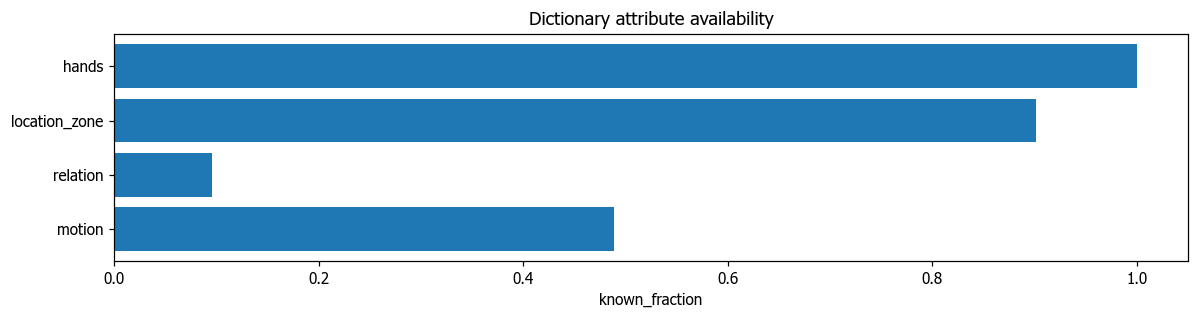

**ตีความ:** ช่องที่มีข้อมูลน้อยจำกัดสิ่งที่ symbolic stream ช่วยได้ แม้คะแนนที่คำนวณจะสูง

,word,variant,hands,location_zone,motion,relation,source
0,5 องค์กรเครือข่าย,0,1,None,[],None,book1:20
1,กบ,0,1,mouth,[],None,book2:None
2,กรกฎาคม,0,2,chest,[],None,book1:49
3,กระชาย (ภาษามือโรงเรียนเศรษฐเสถียรในพระราชูปถัมภ์),0,2,chest,[],None,book3:None
4,กระต่าย,0,2,face,[down],None,book2:None
5,กระถิน (ภาษามือโรงเรียนเศรษฐเสถียรในพระราชูปถัมภ์),0,2,chest,[],None,book3:None
6,กระทิง,0,2,chest,[together],together,book2:None
7,กระท้อน (ภาษามือโรงเรียนเศรษฐเสถียรในพระราชูปถัมภ์),0,2,chest,[],None,book2:None
8,กระเจี๊ยบเขียว (ภาษามือโรงเรียนเศรษฐเสถียรในพระราชูปถัมภ์),0,2,chest,[],None,book3:None
9,กระเจี๊ยบแดง (ภาษามือโรงเรียนเศรษฐเสถียรในพระราชูปถัมภ์),0,2,mouth,[],None,book3:None


**ตัวอย่าง 30 แถวแรก:** ดู source และ variant เพื่อย้อนกลับหนังสือ ไม่ใช้ตารางนี้แทนการตรวจรับรองทั้งหมด

In [5]:
ex.bar(field_coverage, 'attribute', 'known_fraction', 'Dictionary attribute availability', '**ตีความ:** ช่องที่มีข้อมูลน้อยจำกัดสิ่งที่ symbolic stream ช่วยได้ แม้คะแนนที่คำนวณจะสูง')
ex.show_table(dictionary_rows.head(30), '**ตัวอย่าง 30 แถวแรก:** ดู source และ variant เพื่อย้อนกลับหนังสือ ไม่ใช้ตารางนี้แทนการตรวจรับรองทั้งหมด')

## 4. Coverage เทียบ TSL51 — คำนวณใหม่จาก reference จริง

อ่าน `artifacts/runs/seq-v7/tsl51_alignment.json` แยก tune/test ตาม role เดิม ไม่รันโมเดลซ้ำบน test เพื่อเลือกค่า ใช้ exact key เหมือน runtime และไม่ลบวงเล็บหรือรวมคำพ้องเฉพาะในรายงาน

**Uncovered ไม่เท่ากับ OOD ของโมเดล:** คำอาจอยู่ใน bank แต่ไม่มีคำอธิบายใน dictionary จึงเรียกว่า dictionary-uncovered

,split,unique_words,matched,unmatched,vocabulary_overlap,reference_occurrences,occurrence_coverage
0,tune,27,3,24,0.111,417,0.058
1,test,28,4,24,0.143,450,0.080


**อ่านตาราง:** vocabulary_overlap นับชนิดคำ; occurrence_coverage ถ่วงด้วยความถี่จริง จึงบอกว่าคำที่ใช้บ่อยได้รับความช่วยเหลือมากแค่ไหน

,word,occurrences,covered,variants,split
5,กิน,51,False,0,tune
10,ฉัน,48,False,0,tune
3,ชอบ,27,False,0,tune
13,ข้าว,24,False,0,tune
24,เรียน,24,False,0,tune
23,ภาษามือ,24,False,0,tune
16,คุณ,24,False,0,tune
15,หูหนวก,18,False,0,tune
6,ยาย,18,False,0,tune
7,แฟน,18,False,0,tune


**tune:** covered=False หมายถึง runtime หา key ไม่เจอ; คำถี่ที่ขาดมีผลต่อประโยคมากกว่าคำหายที่แทบไม่ใช้

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

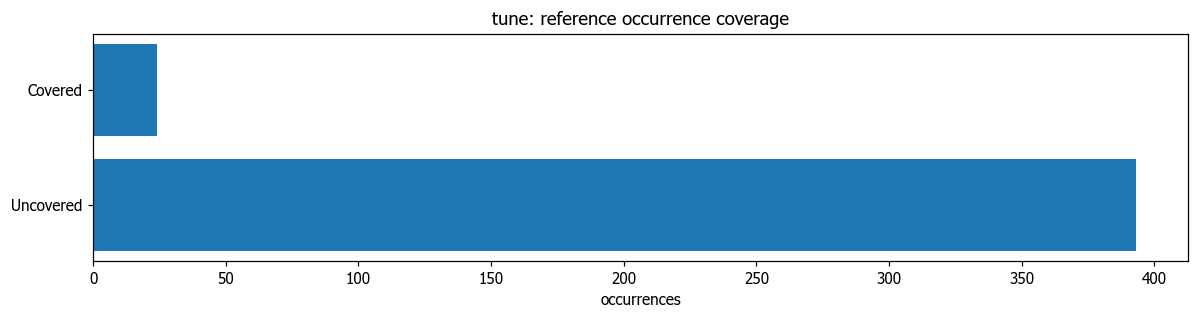

**ตีความ:** กราฟนี้เป็นข้อจำกัดข้อมูล ไม่ใช่ผลความแม่นยำ

,word,occurrences,covered,variants,split
3,ชอบ,54,False,0,test
1,ฉัน,51,False,0,test
10,กิน,45,False,0,test
23,เรียน,30,False,0,test
22,ภาษามือ,30,False,0,test
9,คุณ,27,False,0,test
0,กรุงเทพ,21,False,0,test
2,เที่ยว,21,False,0,test
8,ขนมปัง,18,False,0,test
27,ไข่,15,False,0,test


**test:** covered=False หมายถึง runtime หา key ไม่เจอ; คำถี่ที่ขาดมีผลต่อประโยคมากกว่าคำหายที่แทบไม่ใช้

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

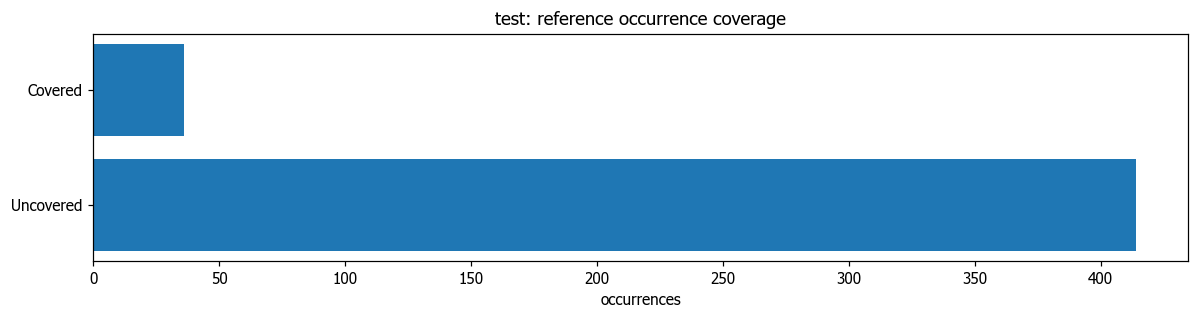

**ตีความ:** กราฟนี้เป็นข้อจำกัดข้อมูล ไม่ใช่ผลความแม่นยำ

In [6]:
coverage_tables = {split:ex.coverage(split) for split in ['tune','test']}
summary=[]
for split,df in coverage_tables.items():
    summary.append(dict(split=split, unique_words=len(df),matched=int(df.covered.sum()),unmatched=int((~df.covered).sum()),
        vocabulary_overlap=df.covered.mean(),reference_occurrences=int(df.occurrences.sum()),
        occurrence_coverage=df.loc[df.covered,'occurrences'].sum()/df.occurrences.sum()))
ex.show_table(pd.DataFrame(summary), '**อ่านตาราง:** vocabulary_overlap นับชนิดคำ; occurrence_coverage ถ่วงด้วยความถี่จริง จึงบอกว่าคำที่ใช้บ่อยได้รับความช่วยเหลือมากแค่ไหน')
for split,df in coverage_tables.items():
    ex.show_table(df, f'**{split}:** covered=False หมายถึง runtime หา key ไม่เจอ; คำถี่ที่ขาดมีผลต่อประโยคมากกว่าคำหายที่แทบไม่ใช้')
    group=df.assign(group=df.covered.map({True:'Covered',False:'Uncovered'})).groupby('group',as_index=False).occurrences.sum()
    ex.bar(group,'group','occurrences',f'{split}: reference occurrence coverage','**ตีความ:** กราฟนี้เป็นข้อจำกัดข้อมูล ไม่ใช่ผลความแม่นยำ')

## 5. รัน inference จริงสองโหมด

เรียก `experiment_analysis.py run` ใน venv จริง สกัด landmark ครั้งเดียวแล้วใช้ร่วมกันเพื่อแยกผลของ fusion จากความแปรปรวน detector สลับลำดับ AI/Hybrid ระหว่างคลิปเพื่อลด order bias บันทึกหลังจบแต่ละคลิป หากโปรแกรมหยุดจะไม่สูญเสียคลิปที่เสร็จแล้ว

รายงานเก็บ hash โมเดล ONNX, pipeline, dictionary, วิดีโอ, config, เวอร์ชันแพ็กเกจ และ raw candidates เพื่อระบุว่าผลเกิดจากอะไร ค่า latency แยก extraction กับ inference; เป็น single-run measurement ไม่ใช่ค่าเฉลี่ย benchmark

`RUN_INFERENCE=True` จะรันใหม่จริง เปลี่ยนเป็น False เมื่อต้องการอ่านผลรอบที่เสร็จแล้วเท่านั้น หาก MediaPipe ใช้บริการ Metal ไม่ได้ ให้รันจาก Jupyter/Terminal ในเครื่องโดยตรง ไม่ใช้ผลจำลองทดแทน

In [7]:
RUN_INFERENCE = True
if RUN_INFERENCE:
    ex.launch_inference()
data = ex.load_results()
ex.show_table(pd.DataFrame([ex.read(ex.OUT/'manifest.json')]).T.rename(columns={0:'value'}),
             '**Provenance:** เก็บพร้อมผลทุกครั้ง; เก็บไฟล์ manifest และ results คู่กันเมื่อนำผลไปเปรียบเทียบรอบใหม่')

[1/6] Extract ฉันยังลืมคุณไม่ได้.MOV
I0000 00:00:1792378950.689556 23091784 init-domain.cc:132] Fiber init: default domain = pthread, concurrency = 8, prefix = pthread-default
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1792378950.876600 23091792 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792378950.894013 23091792 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792378950.896179 23091788 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792378950.896392 23091789 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792378950.896433 230917

,value
created,2026-10-19T10:02:29+0700
python,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/Boom/venv-sign2say/bin/python
versions,"{'torch': '2.14.1', 'onnxruntime': '1.23.2', 'numpy': '1.26.4', 'mediapipe': '1.1.0'}"
hashes,{'Boom/phase2.1/02_hybrid_score/dictionary_attributes.json': 'e19f03cc66ebe2cb91e6eef8f56d09fb8f...
weights,"[0, 0.3]"
shared_landmarks,True
latency_policy,single measurement; extraction shared; model load excluded
spot,"{'lens': [8, 12, 16, 20, 24, 28, 32, 36, 40, 44, 48], 'stride': 4, 'min_inside': 0.6, 'delta': 0..."
bank_note,production conversation bank; not signer-held-out evaluation


**Provenance:** เก็บพร้อมผลทุกครั้ง; เก็บไฟล์ manifest และ results คู่กันเมื่อนำผลไปเปรียบเทียบรอบใหม่

### 5.1 ยืนยันว่า symbolic ถูกใช้จริง

ตรวจ weight=0.30 และ residual ของสมการจากทุก candidate ไม่สรุปจากชื่อไฟล์หรือค่า alpha ของสคริปต์ TSL51 ซึ่งเป็นคนละพารามิเตอร์ ค่า residual ยอมให้คลาดเคลื่อน 0.0002 จากการปัดคะแนน 4 ตำแหน่ง

In [8]:
ex.show_table(ex.fusion_audit(data), '**อ่านตาราง:** all_pass ยืนยันการคำนวณตามสูตร ไม่ได้ยืนยันว่ากฎถูกต้องหรือช่วยเพิ่ม accuracy')

,video,candidates,max_residual,all_pass
0,ฉันยังลืมคุณไม่ได้.MOV,40,0.000,True
1,ฉันแอบชอบคุณ.MOV,40,0.000,True
2,ตอนนี้กำลังเรียนภาษา.MOV,45,0.000,True
3,มีอะไรให้ฉันช่วยไหม.MOV,45,0.000,True
4,เราจะเป็นเพื่อนกันตลอดไป.MOV,40,0.000,True
5,เล่นเกมส์กันไหม.MOV,45,0.000,True


**อ่านตาราง:** all_pass ยืนยันการคำนวณตามสูตร ไม่ได้ยืนยันว่ากฎถูกต้องหรือช่วยเพิ่ม accuracy

## 6. Metric definitions และตารางรายคลิป

| Metric | นิยามและเงื่อนไข |
|---|---|
| WER | newmm ทั้งประโยคชื่อไฟล์และ nearest ที่ต่อเป็นข้อความ เพื่อให้หน่วยตัดคำเหมือนกัน; (S+D+I)/N |
| proposed_gloss_WER | เทียบราย candidate word กับ glosses ที่แสดง ต้องตรวจหน่วยและลำดับท่าก่อนอ้างเป็น gloss WER |
| token_accuracy | จำนวน token ที่ตรงตาม edit alignment / reference count; ไม่ใช่ 1−WER เพราะ insertion |
| sentence_WER | newmm ทั้งประโยคชื่อไฟล์และ sentence output; รวมผลของการเรียบเรียงภาษาใน pipeline |
| exact_sentence | ลำดับ predicted sign tokens ตรงทั้งหมด |
| Segment F1 | label-agnostic maximum one-to-one interval matching IoU≥0.5; ต้องมี timed annotation |
| recall1 / recall5 | reference timed segments ที่จับคู่ IoU≥0.5 และคำจริงอยู่ Top-1/5 / จำนวน reference segments รวมช่วงที่พลาด |
| presence_recall1/5 | ดูคำที่ปรากฏโดยไม่บังคับเวลา เทียบแนวรายงานเพื่อน; จำกัดการนับซ้ำตามจำนวนคำ ไม่ใช่ temporal recall |
| accepted_correct / accepted_precision | คำ accepted ที่ถูกตาม temporal GT / จำนวน accepted; ต้องมี timed annotation |
| count_error | abs(จำนวน predicted segments − จำนวน reference tokens) |
| latency / RTF | extraction + inference; RTF = latency / video duration; ไม่รวมโหลดโมเดล |

**ไม่รายงานตัวเลขเกินหลักฐาน:** หากมีเพียงชื่อประโยค วัด WER ของหน่วยแบ่งคำที่แสดงไว้ได้ แต่ยังไม่อ้างว่าเป็น gloss WER ที่ตรวจลำดับท่าจริงแล้ว Missing metrics เป็น NaN/N/A

,sentence_WER,sentence_output,reference_type,video,mode,n_pred,n_ref,WER,proposed_gloss_WER,token_accuracy,...,accepted_correct,accepted_total,accepted_precision,count_error,inference_s,extraction_s,latency_s,real_time_factor,prediction,reference
0,1.000,,filename sentence; proposed sign tokens,ฉันยังลืมคุณไม่ได้.MOV,ai_only,8,6,1.333,1.333,0.000,...,None,0,None,2,2.507,17.411,19.918,1.627,ยาย | ไป | คุณ | ชอบ | ญาติ | เป็น | อย่า | เกิด,ฉัน | ยัง | ลืม | คุณ | ไม่ | ได้
1,1.000,,filename sentence; proposed sign tokens,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,8,6,1.333,1.333,0.000,...,None,0,None,2,2.273,17.411,19.684,1.608,ญาติ | ไป | คุณ | ชอบ | ญาติ | เป็น | อย่า | เกิด,ฉัน | ยัง | ลืม | คุณ | ไม่ | ได้
2,1.000,,filename sentence; proposed sign tokens,ฉันแอบชอบคุณ.MOV,hybrid030,8,4,2.000,2.000,0.000,...,None,0,None,4,2.566,20.576,23.142,1.780,แฟน | แต่งงาน | เกิด | เป็น | แฟน | แต่งงาน | ข้าว | ถาม,ฉัน | แอบ | ชอบ | คุณ
3,1.000,,filename sentence; proposed sign tokens,ฉันแอบชอบคุณ.MOV,ai_only,8,4,2.000,2.000,0.000,...,None,0,None,4,2.109,20.576,22.685,1.745,แฟน | แต่งงาน | เกิด | เป็น | แฟน | แต่งงาน | ข้าว | ถาม,ฉัน | แอบ | ชอบ | คุณ
4,0.750,เรียน,filename sentence; proposed sign tokens,ตอนนี้กำลังเรียนภาษา.MOV,ai_only,9,4,1.750,1.750,0.500,...,None,1,None,5,2.229,23.017,25.246,1.901,เกิด | ตอนนี้ | เรียน | กรุงเทพ | โสด | วันนี้ | เรียน | กรุงเทพ | คุณ,ตอนนี้ | กำลัง | เรียน | ภาษา
5,0.750,เรียน,filename sentence; proposed sign tokens,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,9,4,1.750,1.750,0.500,...,None,1,None,5,2.785,23.017,25.803,1.943,น้อง | ตอนนี้ | เรียน | กรุงเทพ | โสด | วันนี้ | เรียน | กรุงเทพ | คุณ,ตอนนี้ | กำลัง | เรียน | ภาษา
6,1.000,,filename sentence; proposed sign tokens,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,9,6,1.500,1.500,0.000,...,None,0,None,3,2.453,22.017,24.470,1.738,เกิด | ข้าว | ยาย | ถูก | กิน | เกิด | สิบ | ขนมปัง | ยาย,มี | อะไร | ให้ | ฉัน | ช่วย | ไหม
7,1.000,,filename sentence; proposed sign tokens,มีอะไรให้ฉันช่วยไหม.MOV,ai_only,9,6,1.500,1.500,0.000,...,None,0,None,3,2.895,22.017,24.912,1.769,เกิด | ข้าว | ยาย | ถูก | กิน | เกิด | สิบ | ขนมปัง | ยาย,มี | อะไร | ให้ | ฉัน | ช่วย | ไหม
8,1.000,เพื่อนเพื่อน,filename sentence; proposed sign tokens,เราจะเป็นเพื่อนกันตลอดไป.MOV,ai_only,8,5,1.200,1.600,0.000,...,None,2,None,3,2.552,21.276,23.828,1.584,ยาย | แฟน | เพื่อน | กิน | แต่งงาน | อะไร | เพื่อน | กิน,เรา | จะ | เป็นเพื่อน | กัน | ตลอดไป
9,1.000,เพื่อนเพื่อน,filename sentence; proposed sign tokens,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,8,5,1.200,1.600,0.000,...,None,2,None,3,3.151,21.276,24.427,1.624,ข้าว | แฟน | เพื่อน | กิน | เที่ยว | อะไร | เพื่อน | กิน,เรา | จะ | เป็นเพื่อน | กัน | ตลอดไป


**อ่านตาราง:** WER ต่ำดี token_accuracy สูงดี; ตรวจ reference_tokens หากจำนวนคำดูไม่ตรงท่าจริง. p_correct ไม่ใช่ accuracy. เปรียบเทียบผลในคลิปเดียวกันก่อนค่าเฉลี่ย

,sentence_WER,n_pred,n_ref,WER,proposed_gloss_WER,token_accuracy,exact_sentence,substitutions,deletions,insertions,presence_recall1,presence_recall5,accepted_total,count_error,inference_s,extraction_s,latency_s,real_time_factor
mode,,,,,,,,,,,,,,,,,,
ai_only,0.958,8.500,4.833,1.714,1.739,0.083,0.000,4.500,0.000,3.500,0.111,0.319,0.500,3.667,2.524,21.079,23.603,1.715
hybrid030,0.958,8.500,4.833,1.714,1.739,0.083,0.000,4.500,0.000,3.500,0.111,0.319,0.500,3.667,2.549,21.079,23.629,1.718


**ค่าเฉลี่ย macro:** ให้แต่ละคลิปน้ำหนักเท่ากัน; หกคลิปยังไม่พออ้าง generalization ผู้ทำท่าคนใหม่ และไม่ถือ N/A เป็นศูนย์

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

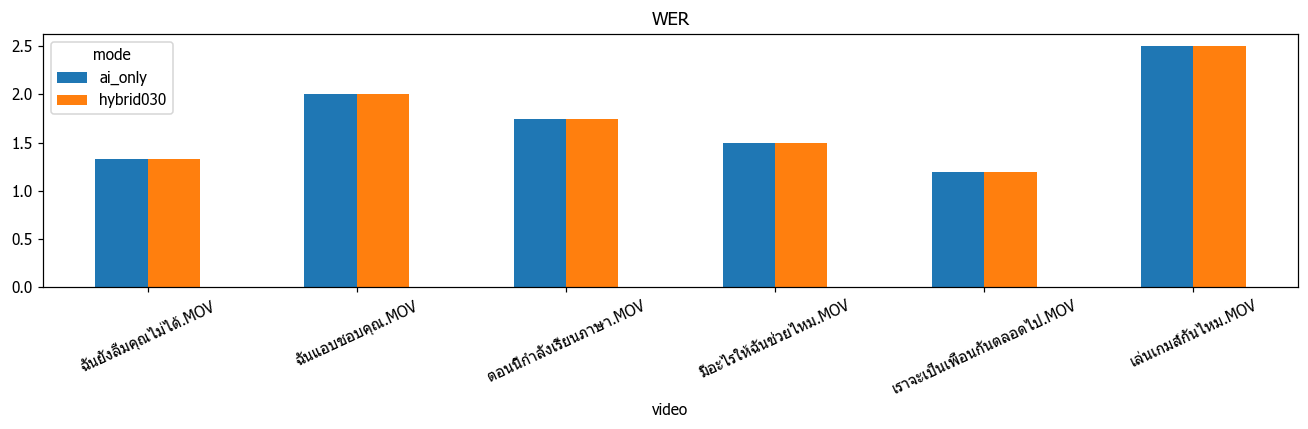

**อ่านกราฟ WER:** เปรียบเทียบคลิปเดียวกันสองโหมด; latency เป็นการวัดครั้งเดียว รวม extraction ที่ใช้ร่วมกัน จึงยังไม่ใช่ latency benchmark ที่ทำซ้ำ

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

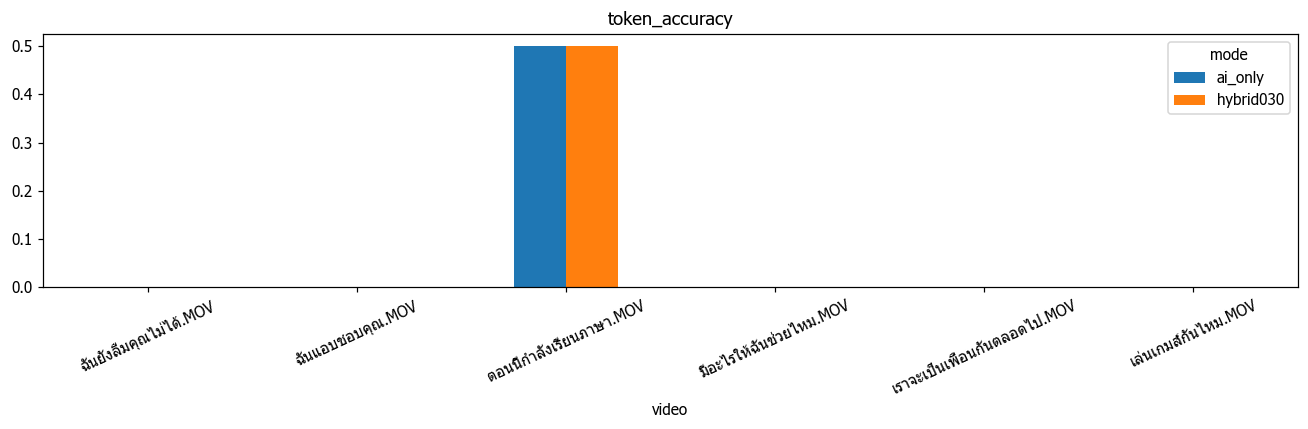

**อ่านกราฟ token_accuracy:** เปรียบเทียบคลิปเดียวกันสองโหมด; latency เป็นการวัดครั้งเดียว รวม extraction ที่ใช้ร่วมกัน จึงยังไม่ใช่ latency benchmark ที่ทำซ้ำ

**segment_F1: N/A** — ยังไม่มี ground truth ที่จำเป็น ไม่แทนด้วย 0

**recall1: N/A** — ยังไม่มี ground truth ที่จำเป็น ไม่แทนด้วย 0

**recall5: N/A** — ยังไม่มี ground truth ที่จำเป็น ไม่แทนด้วย 0

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

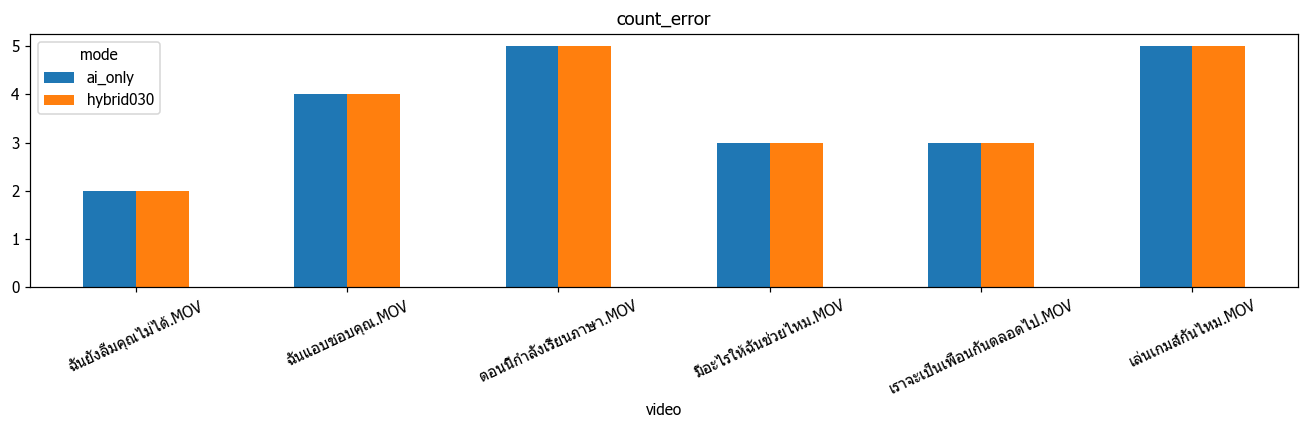

**อ่านกราฟ count_error:** เปรียบเทียบคลิปเดียวกันสองโหมด; latency เป็นการวัดครั้งเดียว รวม extraction ที่ใช้ร่วมกัน จึงยังไม่ใช่ latency benchmark ที่ทำซ้ำ

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

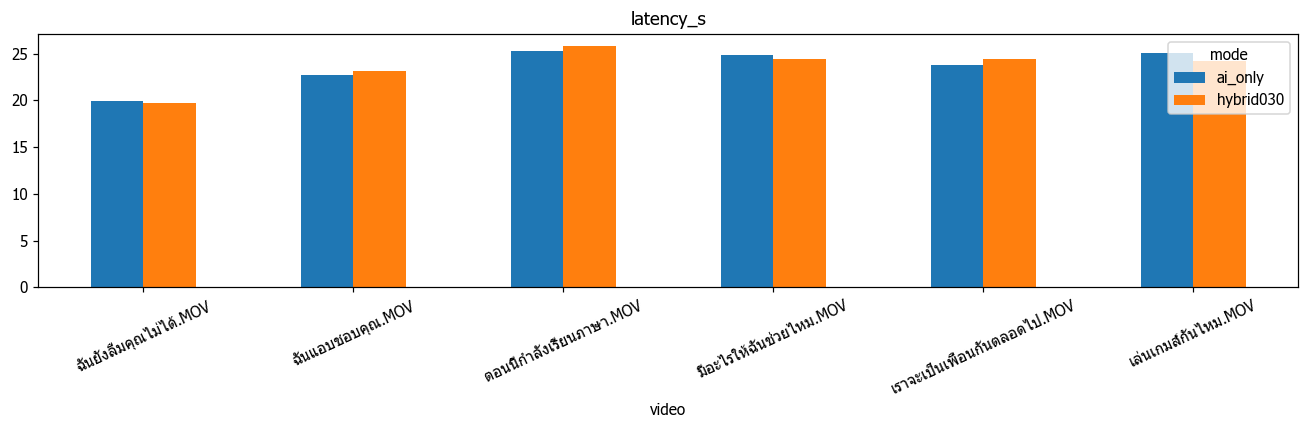

**อ่านกราฟ latency_s:** เปรียบเทียบคลิปเดียวกันสองโหมด; latency เป็นการวัดครั้งเดียว รวม extraction ที่ใช้ร่วมกัน จึงยังไม่ใช่ latency benchmark ที่ทำซ้ำ

,assessment,segments
0,coverage asymmetry; truth not established,7
1,unchanged,44


การเปลี่ยนคำไม่เท่ากับดีขึ้น: helped/harmed แสดงได้เมื่อมีเฉลยเท่านั้น ส่วน boundary changed ต้องตรวจแยกจาก fusion

In [9]:
metrics, segments, candidates = ex.tables(data)
comparison = ex.compare_segments(segments)
ex.show_table(metrics, '**อ่านตาราง:** WER ต่ำดี token_accuracy สูงดี; ตรวจ reference_tokens หากจำนวนคำดูไม่ตรงท่าจริง. p_correct ไม่ใช่ accuracy. เปรียบเทียบผลในคลิปเดียวกันก่อนค่าเฉลี่ย')
mean_metrics=metrics.groupby('mode').mean(numeric_only=True)
ex.show_table(mean_metrics, '**ค่าเฉลี่ย macro:** ให้แต่ละคลิปน้ำหนักเท่ากัน; หกคลิปยังไม่พออ้าง generalization ผู้ทำท่าคนใหม่ และไม่ถือ N/A เป็นศูนย์')
ex.overview(metrics, comparison)

### 6.1 Paired effect size และความไม่แน่นอน

เปรียบเทียบผลคลิปเดียวกันก่อน bootstrap โดย resample คลิปจริง 5,000 ครั้ง seed คงที่ นี่คือการประเมินความไม่แน่นอนของผลจริง ไม่ใช่สร้างคลิปหรือผลปลอม ชุดมีเพียง 6 คลิปและอาจเป็นผู้ทำท่าคนเดียว จึงใช้ CI นี้เชิงสำรวจ ไม่ใช่หลักฐานทั่วไปทุกผู้ใช้

In [10]:
ex.show_table(ex.paired_summary(metrics), '**Delta = Hybrid − AI:** WER/count_error/latency ติดลบคือดีขึ้น; accuracy ติดบวกคือดีขึ้น. CI คร่อม 0 ยังแยกทิศทางไม่ได้; แม้ไม่คร่อมก็ต้องระวังชุดเล็ก')
ex.show_table(ex.score_diagnostics(candidates), '**ตรวจ coverage bias:** เปรียบเทียบคำที่มี/ไม่มี dictionary แยกกัน คะแนน 0 ของคำขาดข้อมูลไม่ใช่หลักฐานว่ารูปท่าขัดกับคำ')

,metric,n_clips,ai_mean,hybrid_mean,delta,ci_low,ci_high,lower,same,higher
0,WER,6,1.714,1.714,0.000,0.000,0.000,0,6,0
1,sentence_WER,6,0.958,0.958,0.000,0.000,0.000,0,6,0
2,token_accuracy,6,0.083,0.083,0.000,0.000,0.000,0,6,0
3,count_error,6,3.667,3.667,0.000,0.000,0.000,0,6,0
4,latency_s,6,23.603,23.629,0.026,-0.411,0.422,3,0,3


**Delta = Hybrid − AI:** WER/count_error/latency ติดลบคือดีขึ้น; accuracy ติดบวกคือดีขึ้น. CI คร่อม 0 ยังแยกทิศทางไม่ได้; แม้ไม่คร่อมก็ต้องระวังชุดเล็ก

,dictionary_covered,candidate_rows,zero_rule_fraction,mean_rule,mean_ai,mean_final
0,False,235,1.000,0.000,0.200,0.140
1,True,20,0.300,0.456,0.203,0.279


**ตรวจ coverage bias:** เปรียบเทียบคำที่มี/ไม่มี dictionary แยกกัน คะแนน 0 ของคำขาดข้อมูลไม่ใช่หลักฐานว่ารูปท่าขัดกับคำ

## 7. Segment-level deep dive

ตารางนี้เก็บ start/end time, Top-5, cosine, AI softmax, rule score, final score และ dictionary coverage แยกกัน ✔/✗ อิงเฉลย: ถ้ามี timed labels ใช้ temporal match; หากมีเพียง reference tokens ใช้ edit alignment ซึ่งบอกความตรงลำดับแต่ยังไม่พิสูจน์ว่าขอบเขตท่านั้นถูก

Missing hand rates ในโค้ดปัจจุบันวัดจาก wrist confidence ไม่ใช่จำนวน 21 finger landmarks ที่เห็นครบ ห้ามตีความว่าเห็นรูปนิ้วครบทั้งหมด

In [11]:
ex.show_table(segments, '**อ่านตาราง:** observed_attributes เป็นหลักฐานที่ symbolic ใช้จริง; ค่า ? คือไม่สามารถระบุ reference ของช่วงนั้นได้แน่ชัด')
ex.show_table(candidates, '**Top-5:** แสดงทุกคลิปทุกช่วง ไม่มีการเลือกเฉพาะตัวอย่างที่ดี; final_score มีเฉพาะ Hybrid')
ex.show_table(segments.groupby('mode')[['top1_covered','top5_covered']].mean(),
             '**Coverage ต่อ segment:** top1_covered คือคำที่เลือกมี dictionary; top5_covered คืออย่างน้อยหนึ่งผู้สมัครมี dictionary ไม่ใช่ทุกตัวมีข้อมูลเท่าเทียมกัน')

,video,mode,segment,t0,t1,word,status,p_correct,ground_truth,correctness,top1_covered,top5_covered,left_observed,right_observed,observed_attributes
0,ฉันยังลืมคุณไม่ได้.MOV,ai_only,0,0.800,2.720,ยาย,uncertain,0.099,None,?,False,False,NaN,NaN,{}
1,ฉันยังลืมคุณไม่ได้.MOV,ai_only,1,2.880,3.840,ไป,uncertain,0.120,None,?,False,True,NaN,NaN,{}
2,ฉันยังลืมคุณไม่ได้.MOV,ai_only,2,3.840,5.280,คุณ,unknown,0.058,ฉัน,✗,False,False,NaN,NaN,{}
3,ฉันยังลืมคุณไม่ได้.MOV,ai_only,3,5.280,5.920,ชอบ,uncertain,0.524,ยัง,✗,False,False,NaN,NaN,{}
4,ฉันยังลืมคุณไม่ได้.MOV,ai_only,4,6.560,8.480,ญาติ,uncertain,0.272,ลืม,✗,False,False,NaN,NaN,{}
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97,เล่นเกมส์กันไหม.MOV,ai_only,4,7.360,8.480,เกิด,uncertain,0.156,None,?,False,False,NaN,NaN,{}
98,เล่นเกมส์กันไหม.MOV,ai_only,5,8.480,10.080,ถูก,uncertain,0.679,เล่น,✗,False,False,NaN,NaN,{}
99,เล่นเกมส์กันไหม.MOV,ai_only,6,11.520,12.320,ญาติ,uncertain,0.242,เกมส์,✗,False,False,NaN,NaN,{}
100,เล่นเกมส์กันไหม.MOV,ai_only,7,12.320,13.280,เกิด,unknown,0.051,กัน,✗,False,False,NaN,NaN,{}


**อ่านตาราง:** observed_attributes เป็นหลักฐานที่ symbolic ใช้จริง; ค่า ? คือไม่สามารถระบุ reference ของช่วงนั้นได้แน่ชัด

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
0,ฉันยังลืมคุณไม่ได้.MOV,ai_only,0,0.800,2.720,1,ยาย,0.653,NaN,NaN,NaN,False,None,?
1,ฉันยังลืมคุณไม่ได้.MOV,ai_only,0,0.800,2.720,2,แฟน,0.634,NaN,NaN,NaN,False,None,?
2,ฉันยังลืมคุณไม่ได้.MOV,ai_only,0,0.800,2.720,3,ฉัน,0.610,NaN,NaN,NaN,False,None,?
3,ฉันยังลืมคุณไม่ได้.MOV,ai_only,0,0.800,2.720,4,ข้าว,0.575,NaN,NaN,NaN,False,None,?
4,ฉันยังลืมคุณไม่ได้.MOV,ai_only,0,0.800,2.720,5,ญาติ,0.664,NaN,NaN,NaN,False,None,?
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
505,เล่นเกมส์กันไหม.MOV,ai_only,8,13.280,15.040,1,ไม่ดี,0.590,NaN,NaN,NaN,False,ไหม,✗
506,เล่นเกมส์กันไหม.MOV,ai_only,8,13.280,15.040,2,ถูก,0.701,NaN,NaN,NaN,False,ไหม,✗
507,เล่นเกมส์กันไหม.MOV,ai_only,8,13.280,15.040,3,ยาย,0.600,NaN,NaN,NaN,False,ไหม,✗
508,เล่นเกมส์กันไหม.MOV,ai_only,8,13.280,15.040,4,ถูกต้อง,0.457,NaN,NaN,NaN,False,ไหม,✗


**Top-5:** แสดงทุกคลิปทุกช่วง ไม่มีการเลือกเฉพาะตัวอย่างที่ดี; final_score มีเฉพาะ Hybrid

,top1_covered,top5_covered
mode,,
ai_only,0.059,0.294
hybrid030,0.078,0.294


**Coverage ต่อ segment:** top1_covered คือคำที่เลือกมี dictionary; top5_covered คืออย่างน้อยหนึ่งผู้สมัครมี dictionary ไม่ใช่ทุกตัวมีข้อมูลเท่าเทียมกัน

### 7.1 คำเปลี่ยนตรงไหน — ช่วยหรือทำให้แย่ลง?

จับคู่ช่วงด้วย `(video,t0,t1)` ที่เหมือนกันเท่านั้น กรณี boundary เปลี่ยนแยกออก ไม่จับช่วงที่ 2 ของ AI ไปเทียบช่วงที่ 2 ของ Hybrid โดยอัตโนมัติ สาเหตุที่แสดงเป็น diagnosis เบื้องต้น ไม่ใช่ผลพิสูจน์เชิงเหตุและผล

In [12]:
ex.show_table(comparison, '**อ่านตาราง:** helped/harmed อิงเฉลยที่มี; เมื่อใช้ token alignment อย่างเดียวควรเปิดวิดีโอยืนยันอีกครั้ง')
changes=comparison[comparison.changed]
ex.show_table(changes.groupby(['word_ai','word_hybrid','assessment'],dropna=False,observed=True).size().rename('count').reset_index(),
             '**Confusion/change pairs:** AI → Hybrid คือคู่คำที่สลับ ไม่จำเป็นต้องเป็น true confusion ถ้ายังไม่มี timed ground truth')
errors=segments[segments.ground_truth.notna() & (segments.ground_truth!=segments.word)]
ex.show_table(errors.groupby(['mode','ground_truth','word'],dropna=False).size().rename('count').reset_index(),
             '**Reference → prediction:** คู่สับสนตาม alignment; ควรดูภาพประกอบและช่วงเวลาก่อนสรุปว่าเป็น recognition error หรือ segmentation error')

,video,mode_ai,segment_ai,t0,t1,word_ai,status_ai,p_correct_ai,ground_truth_ai,correctness_ai,...,ground_truth_hybrid,correctness_hybrid,top1_covered_hybrid,top5_covered_hybrid,left_observed_hybrid,right_observed_hybrid,observed_attributes_hybrid,_merge,changed,assessment
0,ฉันยังลืมคุณไม่ได้.MOV,ai_only,0,0.800,2.720,ยาย,uncertain,0.099,None,?,...,None,?,False,False,0.000,0.812,"{""hands"": 1, ""location_zone"": ""face"", ""relation"": null, ""motion"": [""circle"", ""down""], ""hand_obse...",both,True,coverage asymmetry; truth not established
1,ฉันยังลืมคุณไม่ได้.MOV,ai_only,1,2.880,3.840,ไป,uncertain,0.120,None,?,...,None,?,False,True,0.000,1.000,"{""hands"": 1, ""location_zone"": ""face"", ""relation"": null, ""motion"": [""circle""], ""hand_observed"": {...",both,False,unchanged
2,ฉันยังลืมคุณไม่ได้.MOV,ai_only,2,3.840,5.280,คุณ,unknown,0.058,ฉัน,✗,...,ฉัน,✗,False,False,0.000,1.000,"{""hands"": 1, ""location_zone"": ""face"", ""relation"": null, ""motion"": [""circle""], ""hand_observed"": {...",both,False,unchanged
3,ฉันยังลืมคุณไม่ได้.MOV,ai_only,3,5.280,5.920,ชอบ,uncertain,0.524,ยัง,✗,...,ยัง,✗,False,False,0.000,1.000,"{""hands"": 1, ""location_zone"": ""face"", ""relation"": null, ""motion"": [""circle""], ""hand_observed"": {...",both,False,unchanged
4,ฉันยังลืมคุณไม่ได้.MOV,ai_only,4,6.560,8.480,ญาติ,uncertain,0.272,ลืม,✗,...,ลืม,✗,False,False,0.000,0.792,"{""hands"": 1, ""location_zone"": ""face"", ""relation"": null, ""motion"": [""circle"", ""down""], ""hand_obse...",both,False,unchanged
5,ฉันยังลืมคุณไม่ได้.MOV,ai_only,5,8.480,10.400,เป็น,unknown,0.032,คุณ,✗,...,คุณ,✗,False,False,0.000,1.000,"{""hands"": 1, ""location_zone"": ""face"", ""relation"": null, ""motion"": [""circle""], ""hand_observed"": {...",both,False,unchanged
6,ฉันยังลืมคุณไม่ได้.MOV,ai_only,6,10.400,11.040,อย่า,uncertain,0.431,ไม่,✗,...,ไม่,✗,False,True,0.000,1.000,"{""hands"": 1, ""location_zone"": ""face"", ""relation"": null, ""motion"": [""circle"", ""up""], ""hand_observ...",both,False,unchanged
7,ฉันยังลืมคุณไม่ได้.MOV,ai_only,7,11.040,11.840,เกิด,uncertain,0.287,ได้,✗,...,ได้,✗,False,False,0.000,1.000,"{""hands"": 1, ""location_zone"": ""face"", ""relation"": null, ""motion"": [""down""], ""hand_observed"": {""l...",both,False,unchanged
8,ฉันแอบชอบคุณ.MOV,ai_only,0,0.320,2.240,แฟน,uncertain,0.389,None,?,...,None,?,False,False,0.375,0.583,"{""hands"": 1, ""location_zone"": ""chest"", ""relation"": null, ""motion"": [""down""], ""hand_observed"": {""...",both,False,unchanged
9,ฉันแอบชอบคุณ.MOV,ai_only,1,2.240,3.680,แต่งงาน,uncertain,0.260,None,?,...,None,?,False,True,1.000,1.000,"{""hands"": 2, ""location_zone"": ""low"", ""relation"": null, ""motion"": [""circle""], ""hand_observed"": {""...",both,False,unchanged


**อ่านตาราง:** helped/harmed อิงเฉลยที่มี; เมื่อใช้ token alignment อย่างเดียวควรเปิดวิดีโอยืนยันอีกครั้ง

,word_ai,word_hybrid,assessment,count
0,ยาย,ข้าว,coverage asymmetry; truth not established,1
1,ยาย,ญาติ,coverage asymmetry; truth not established,1
2,เกิด,ฉัน,coverage asymmetry; truth not established,1
3,เกิด,น้อง,coverage asymmetry; truth not established,1
4,เกิด,ยินดีด้วย,coverage asymmetry; truth not established,1
5,แต่งงาน,เที่ยว,coverage asymmetry; truth not established,1
6,ไม่ดี,ยาย,coverage asymmetry; truth not established,1


**Confusion/change pairs:** AI → Hybrid คือคู่คำที่สลับ ไม่จำเป็นต้องเป็น true confusion ถ้ายังไม่มี timed ground truth

,mode,ground_truth,word,count
0,ai_only,กัน,เกิด,1
1,ai_only,กัน,เพื่อน,1
2,ai_only,กำลัง,วันนี้,1
3,ai_only,คุณ,ถาม,1
4,ai_only,คุณ,เป็น,1
5,ai_only,จะ,แต่งงาน,1
6,ai_only,ฉัน,คุณ,1
7,ai_only,ฉัน,สิบ,1
8,ai_only,ฉัน,แฟน,1
9,ai_only,ชอบ,ข้าว,1


**Reference → prediction:** คู่สับสนตาม alignment; ควรดูภาพประกอบและช่วงเวลาก่อนสรุปว่าเป็น recognition error หรือ segmentation error

### 7.2 Visual analysis ทั้ง 6 คลิป

แต่ละคลิปมี timeline สองโหมด และภาพเฟรมจริงกลางช่วงพร้อมกราฟสามคะแนน ทุกกราฟตามด้วยคำอธิบายและตารางละเอียด การตรวจ motion ต้องกลับไปดูวิดีโอทั้งช่วง ภาพเดียวไม่ยืนยันการวน/ยก/ลด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

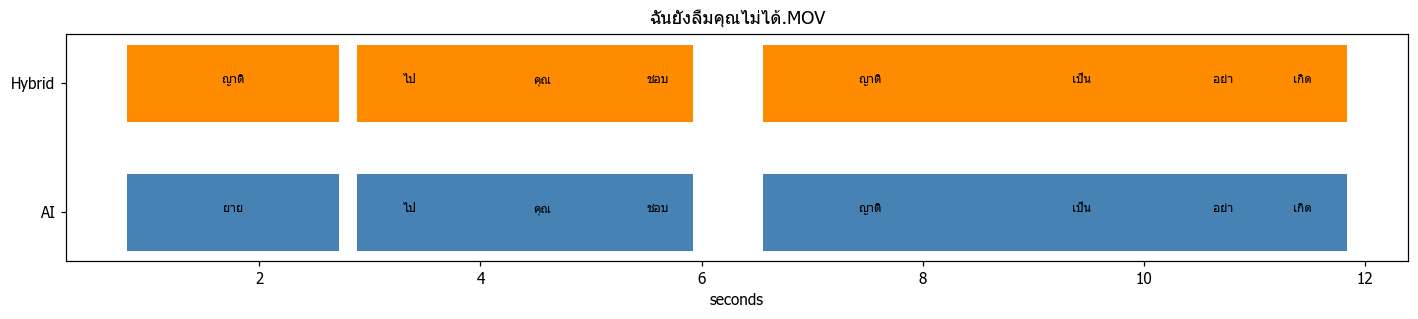

**Timeline:** ตรวจว่าจำนวนและขอบเขตช่วงเปลี่ยนหรือไม่ เพราะ pipeline มี postprocessing หลัง fusion; ความต่างจึงไม่ได้จำกัดอยู่ที่อันดับคำเสมอ

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

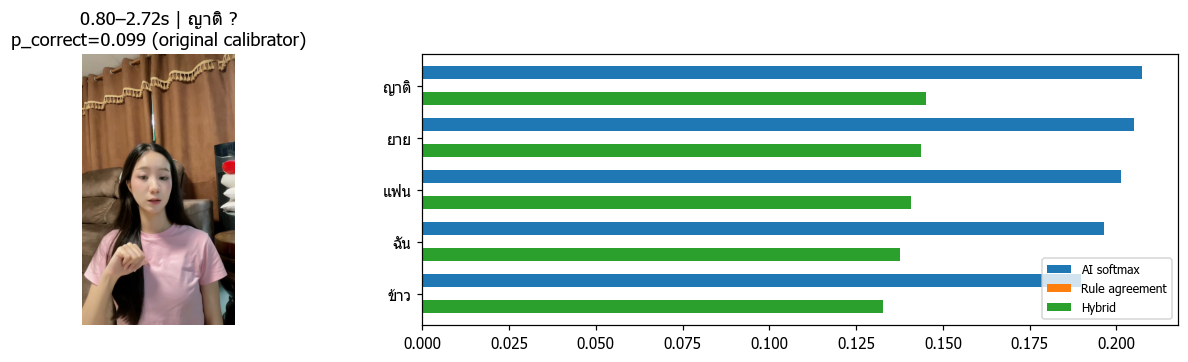

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 1, "location_zone": "face", "relation": null, "motion": ["circle", "down"], "hand_observed": {"left": 0.0, "right": 0.812}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
40,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,0,0.800,2.720,1,ญาติ,0.664,0.207,0.000,0.145,False,None,?
41,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,0,0.800,2.720,2,ยาย,0.653,0.205,0.000,0.144,False,None,?
42,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,0,0.800,2.720,3,แฟน,0.634,0.201,0.000,0.141,False,None,?
43,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,0,0.800,2.720,4,ฉัน,0.610,0.196,0.000,0.138,False,None,?
44,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,0,0.800,2.720,5,ข้าว,0.575,0.190,0.000,0.133,False,None,?


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

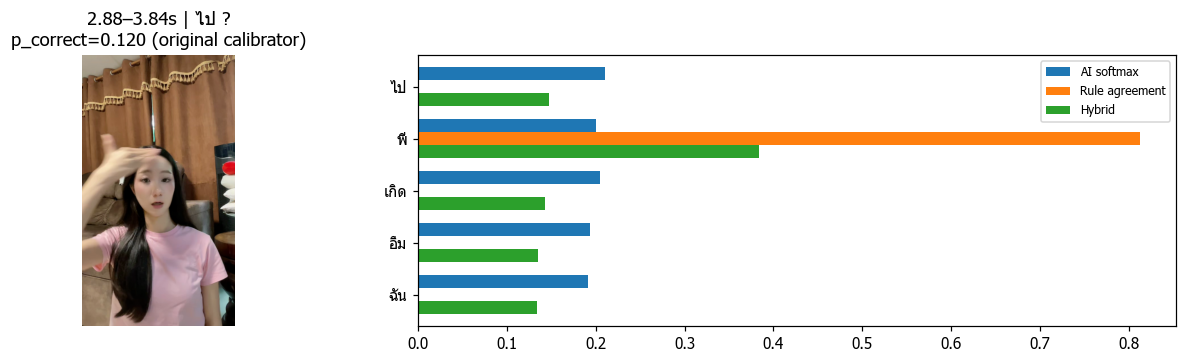

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 1, "location_zone": "face", "relation": null, "motion": ["circle"], "hand_observed": {"left": 0.0, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
45,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,1,2.880,3.840,1,ไป,0.449,0.210,0.000,0.147,False,None,?
46,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,1,2.880,3.840,2,พี่,0.400,0.200,0.812,0.384,True,None,?
47,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,1,2.880,3.840,3,เกิด,0.420,0.204,0.000,0.143,False,None,?
48,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,1,2.880,3.840,4,อิ่ม,0.364,0.193,0.000,0.135,False,None,?
49,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,1,2.880,3.840,5,ฉัน,0.354,0.191,0.000,0.134,False,None,?


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

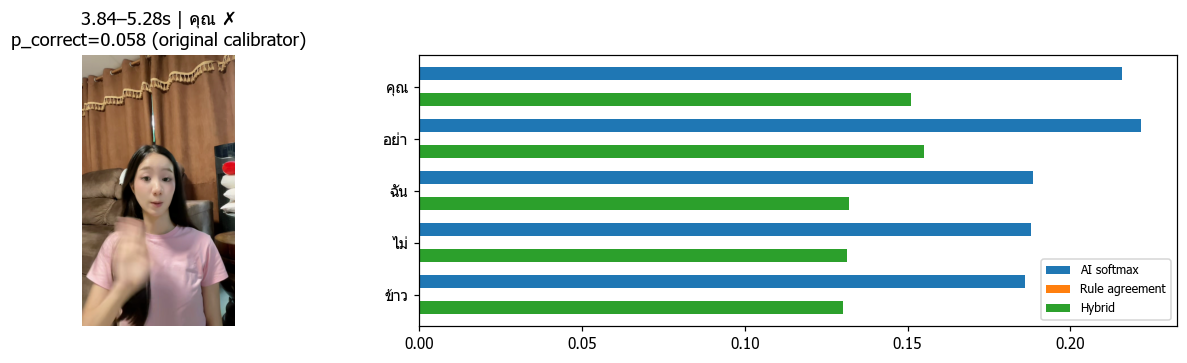

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 1, "location_zone": "face", "relation": null, "motion": ["circle"], "hand_observed": {"left": 0.0, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
50,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,2,3.840,5.280,1,คุณ,0.584,0.216,0.000,0.151,False,ฉัน,✗
51,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,2,3.840,5.280,2,อย่า,0.611,0.222,0.000,0.155,False,ฉัน,✗
52,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,2,3.840,5.280,3,ฉัน,0.450,0.189,0.000,0.132,False,ฉัน,✔
53,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,2,3.840,5.280,4,ไม่,0.446,0.188,0.000,0.132,False,ฉัน,✗
54,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,2,3.840,5.280,5,ข้าว,0.437,0.186,0.000,0.130,False,ฉัน,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

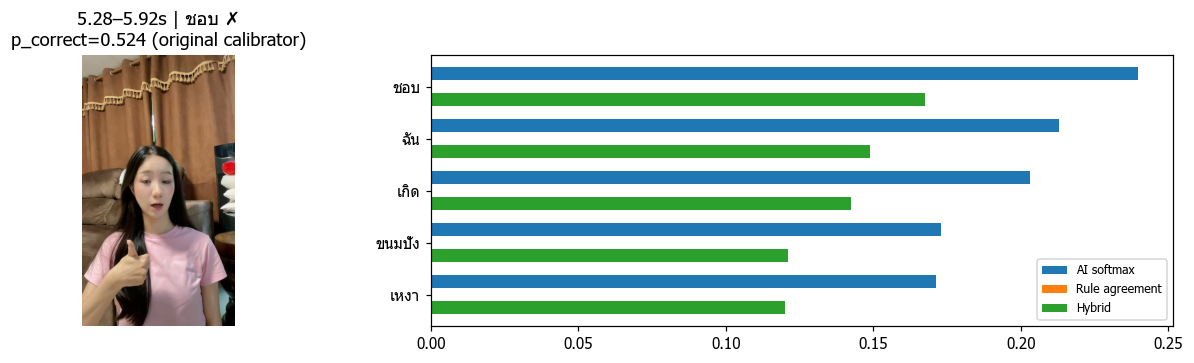

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 1, "location_zone": "face", "relation": null, "motion": ["circle"], "hand_observed": {"left": 0.0, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
55,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,3,5.280,5.920,1,ชอบ,0.655,0.240,0.000,0.168,False,ยัง,✗
56,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,3,5.280,5.920,2,ฉัน,0.536,0.213,0.000,0.149,False,ยัง,✗
57,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,3,5.280,5.920,3,เกิด,0.490,0.203,0.000,0.142,False,ยัง,✗
58,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,3,5.280,5.920,4,ขนมปัง,0.328,0.173,0.000,0.121,False,ยัง,✗
59,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,3,5.280,5.920,5,เหงา,0.320,0.171,0.000,0.120,False,ยัง,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

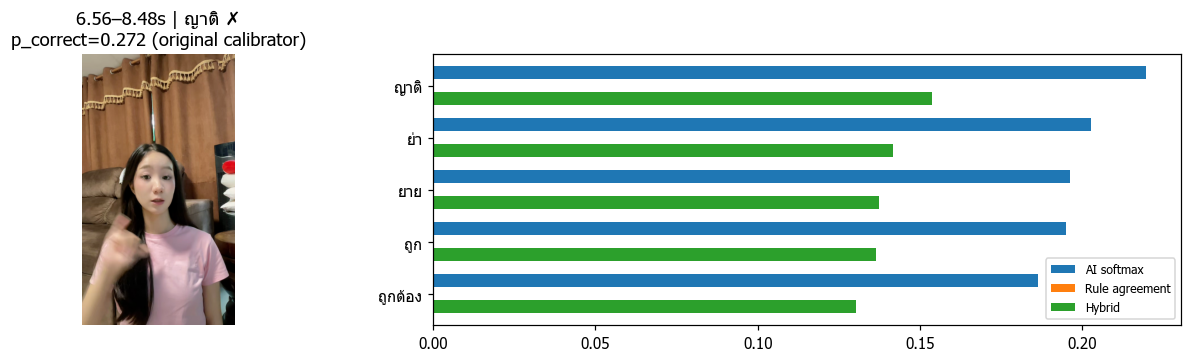

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 1, "location_zone": "face", "relation": null, "motion": ["circle", "down"], "hand_observed": {"left": 0.0, "right": 0.792}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
60,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,4,6.560,8.480,1,ญาติ,0.642,0.220,0.000,0.154,False,ลืม,✗
61,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,4,6.560,8.480,2,ย่า,0.561,0.203,0.000,0.142,False,ลืม,✗
62,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,4,6.560,8.480,3,ยาย,0.529,0.196,0.000,0.137,False,ลืม,✗
63,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,4,6.560,8.480,4,ถูก,0.523,0.195,0.000,0.137,False,ลืม,✗
64,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,4,6.560,8.480,5,ถูกต้อง,0.477,0.186,0.000,0.130,False,ลืม,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

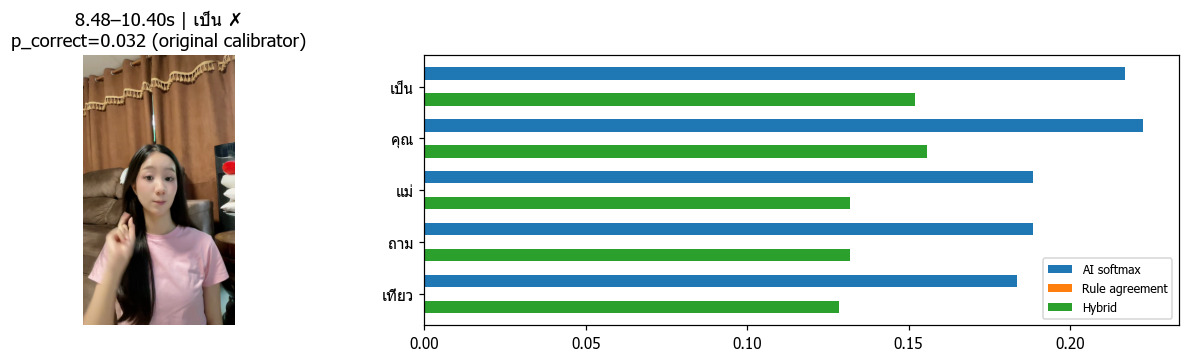

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 1, "location_zone": "face", "relation": null, "motion": ["circle"], "hand_observed": {"left": 0.0, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
65,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,5,8.480,10.400,1,เป็น,0.531,0.217,0.000,0.152,False,คุณ,✗
66,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,5,8.480,10.400,2,คุณ,0.556,0.222,0.000,0.156,False,คุณ,✔
67,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,5,8.480,10.400,3,แม่,0.390,0.188,0.000,0.132,False,คุณ,✗
68,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,5,8.480,10.400,4,ถาม,0.390,0.188,0.000,0.132,False,คุณ,✗
69,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,5,8.480,10.400,5,เที่ยว,0.364,0.184,0.000,0.128,False,คุณ,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

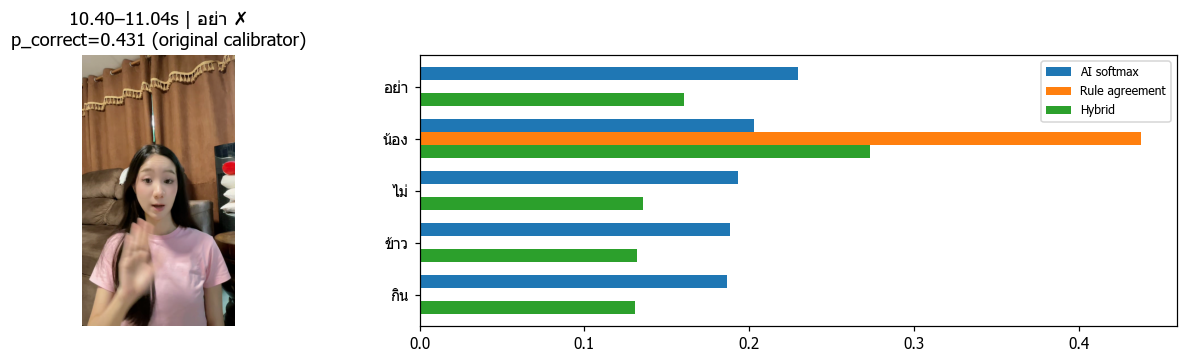

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 1, "location_zone": "face", "relation": null, "motion": ["circle", "up"], "hand_observed": {"left": 0.0, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
70,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,6,10.400,11.040,1,อย่า,0.542,0.230,0.000,0.161,False,ไม่,✗
71,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,6,10.400,11.040,2,น้อง,0.417,0.203,0.438,0.273,True,ไม่,✗
72,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,6,10.400,11.040,3,ไม่,0.369,0.193,0.000,0.135,False,ไม่,✔
73,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,6,10.400,11.040,4,ข้าว,0.343,0.188,0.000,0.132,False,ไม่,✗
74,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,6,10.400,11.040,5,กิน,0.335,0.187,0.000,0.131,False,ไม่,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

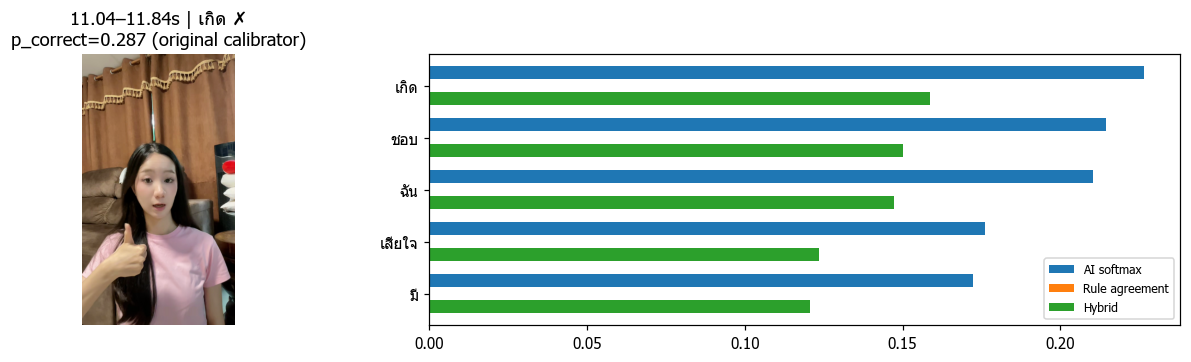

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 1, "location_zone": "face", "relation": null, "motion": ["down"], "hand_observed": {"left": 0.0, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
75,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,7,11.040,11.840,1,เกิด,0.577,0.227,0.000,0.159,False,ได้,✗
76,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,7,11.040,11.840,2,ชอบ,0.522,0.214,0.000,0.150,False,ได้,✗
77,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,7,11.040,11.840,3,ฉัน,0.502,0.210,0.000,0.147,False,ได้,✗
78,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,7,11.040,11.840,4,เสียใจ,0.325,0.176,0.000,0.123,False,ได้,✗
79,ฉันยังลืมคุณไม่ได้.MOV,hybrid030,7,11.040,11.840,5,มี,0.303,0.172,0.000,0.121,False,ได้,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

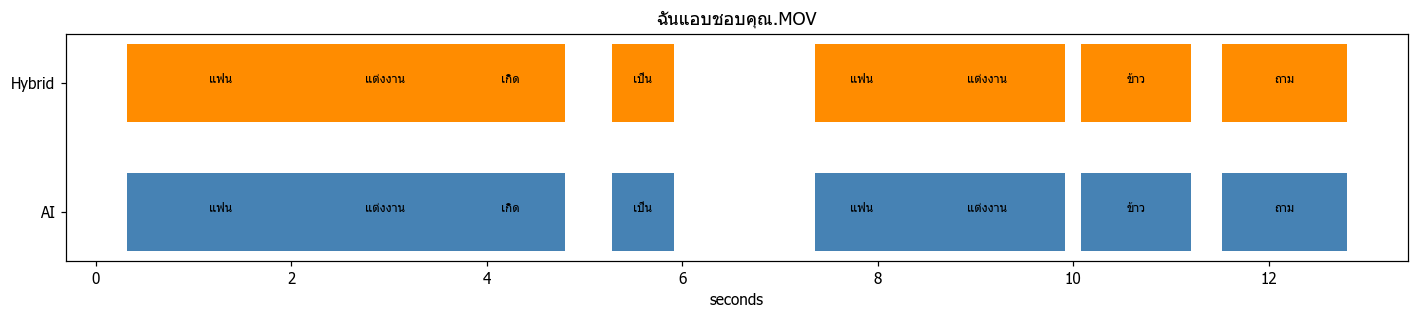

**Timeline:** ตรวจว่าจำนวนและขอบเขตช่วงเปลี่ยนหรือไม่ เพราะ pipeline มี postprocessing หลัง fusion; ความต่างจึงไม่ได้จำกัดอยู่ที่อันดับคำเสมอ

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

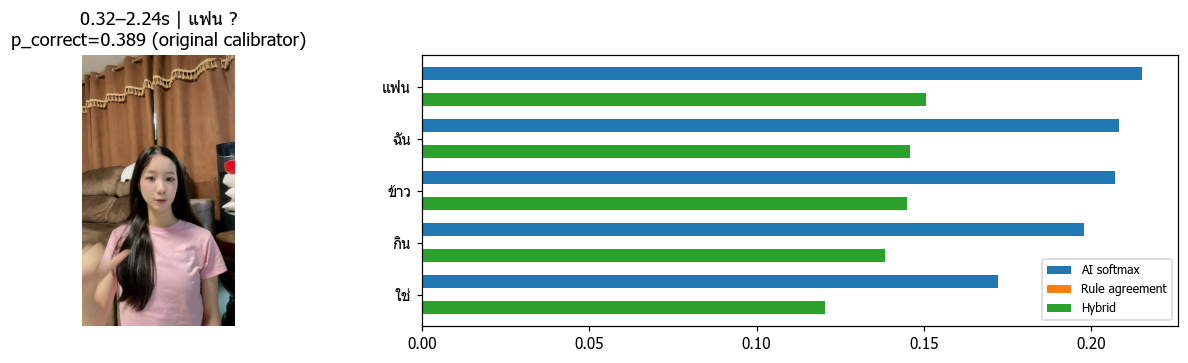

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 1, "location_zone": "chest", "relation": null, "motion": ["down"], "hand_observed": {"left": 0.375, "right": 0.583}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
80,ฉันแอบชอบคุณ.MOV,hybrid030,0,0.320,2.240,1,แฟน,0.647,0.215,0.000,0.150,False,None,?
81,ฉันแอบชอบคุณ.MOV,hybrid030,0,0.320,2.240,2,ฉัน,0.615,0.208,0.000,0.146,False,None,?
82,ฉันแอบชอบคุณ.MOV,hybrid030,0,0.320,2.240,3,ข้าว,0.608,0.207,0.000,0.145,False,None,?
83,ฉันแอบชอบคุณ.MOV,hybrid030,0,0.320,2.240,4,กิน,0.563,0.198,0.000,0.138,False,None,?
84,ฉันแอบชอบคุณ.MOV,hybrid030,0,0.320,2.240,5,ใช่,0.424,0.172,0.000,0.120,False,None,?


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

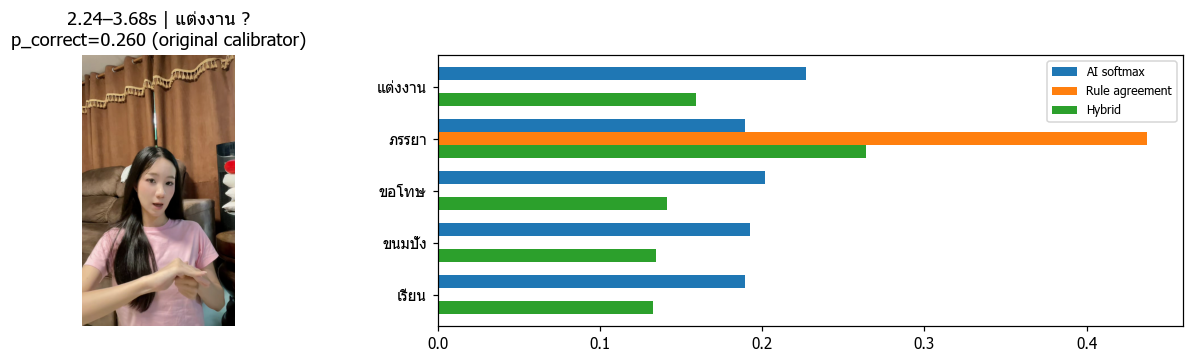

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "low", "relation": null, "motion": ["circle"], "hand_observed": {"left": 1.0, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
85,ฉันแอบชอบคุณ.MOV,hybrid030,1,2.240,3.680,1,แต่งงาน,0.528,0.227,0.000,0.159,False,None,?
86,ฉันแอบชอบคุณ.MOV,hybrid030,1,2.240,3.680,2,ภรรยา,0.347,0.190,0.438,0.264,True,None,?
87,ฉันแอบชอบคุณ.MOV,hybrid030,1,2.240,3.680,3,ขอโทษ,0.410,0.202,0.000,0.141,False,None,?
88,ฉันแอบชอบคุณ.MOV,hybrid030,1,2.240,3.680,4,ขนมปัง,0.361,0.192,0.000,0.134,False,None,?
89,ฉันแอบชอบคุณ.MOV,hybrid030,1,2.240,3.680,5,เรียน,0.347,0.189,0.000,0.133,False,None,?


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

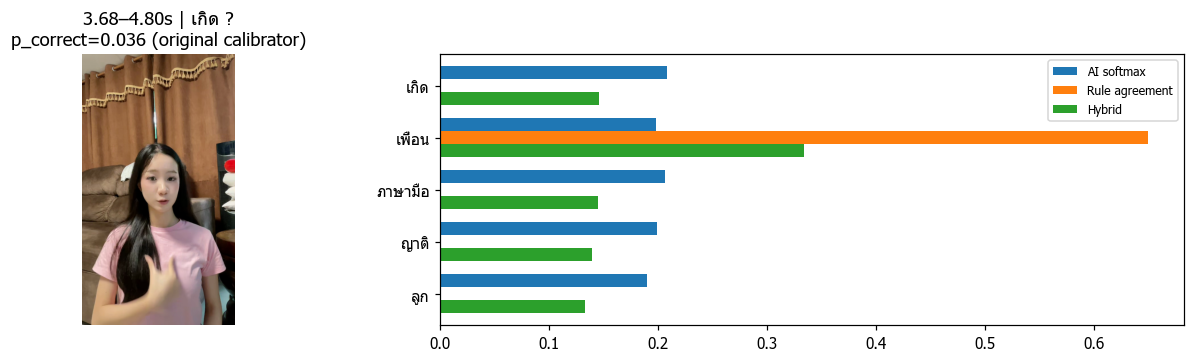

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "chest", "relation": null, "motion": ["circle"], "hand_observed": {"left": 0.857, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
90,ฉันแอบชอบคุณ.MOV,hybrid030,2,3.680,4.800,1,เกิด,0.419,0.208,0.000,0.145,False,None,?
91,ฉันแอบชอบคุณ.MOV,hybrid030,2,3.680,4.800,2,เพื่อน,0.370,0.198,0.650,0.333,True,None,?
92,ฉันแอบชอบคุณ.MOV,hybrid030,2,3.680,4.800,3,ภาษามือ,0.412,0.206,0.000,0.144,False,None,?
93,ฉันแอบชอบคุณ.MOV,hybrid030,2,3.680,4.800,4,ญาติ,0.374,0.199,0.000,0.139,False,None,?
94,ฉันแอบชอบคุณ.MOV,hybrid030,2,3.680,4.800,5,ลูก,0.328,0.190,0.000,0.133,False,None,?


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

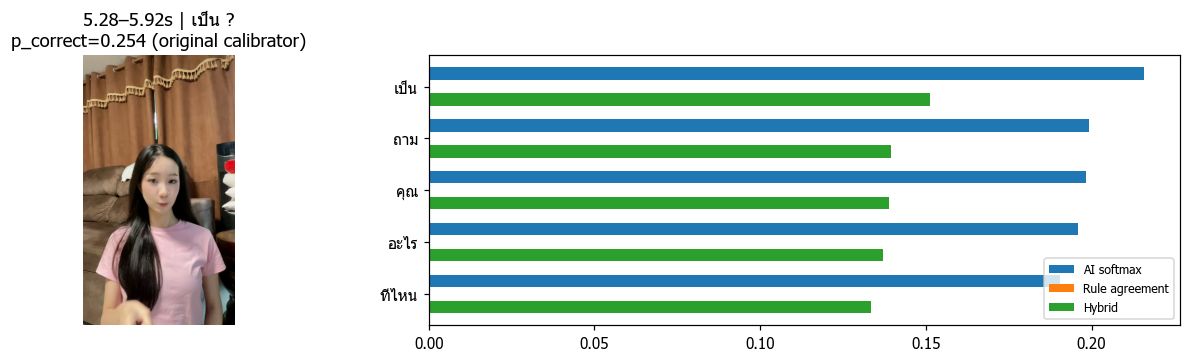

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "low", "relation": null, "motion": ["down"], "hand_observed": {"left": 1.0, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
95,ฉันแอบชอบคุณ.MOV,hybrid030,3,5.280,5.920,1,เป็น,0.555,0.216,0.000,0.151,False,None,?
96,ฉันแอบชอบคุณ.MOV,hybrid030,3,5.280,5.920,2,ถาม,0.475,0.199,0.000,0.140,False,None,?
97,ฉันแอบชอบคุณ.MOV,hybrid030,3,5.280,5.920,3,คุณ,0.470,0.198,0.000,0.139,False,None,?
98,ฉันแอบชอบคุณ.MOV,hybrid030,3,5.280,5.920,4,อะไร,0.458,0.196,0.000,0.137,False,None,?
99,ฉันแอบชอบคุณ.MOV,hybrid030,3,5.280,5.920,5,ที่ไหน,0.429,0.190,0.000,0.133,False,None,?


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

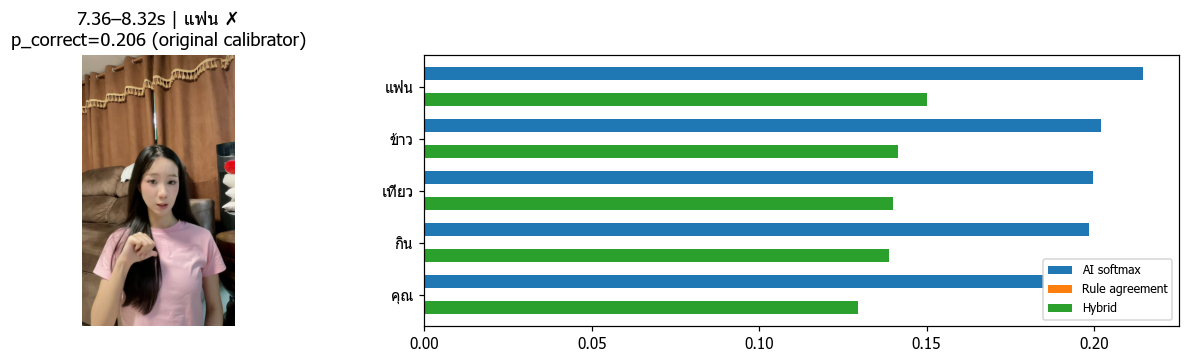

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "chest", "relation": null, "motion": ["down"], "hand_observed": {"left": 0.542, "right": 0.833}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
100,ฉันแอบชอบคุณ.MOV,hybrid030,4,7.360,8.320,1,แฟน,0.515,0.214,0.000,0.150,False,ฉัน,✗
101,ฉันแอบชอบคุณ.MOV,hybrid030,4,7.360,8.320,2,ข้าว,0.456,0.202,0.000,0.142,False,ฉัน,✗
102,ฉันแอบชอบคุณ.MOV,hybrid030,4,7.360,8.320,3,เที่ยว,0.444,0.200,0.000,0.140,False,ฉัน,✗
103,ฉันแอบชอบคุณ.MOV,hybrid030,4,7.360,8.320,4,กิน,0.437,0.198,0.000,0.139,False,ฉัน,✗
104,ฉันแอบชอบคุณ.MOV,hybrid030,4,7.360,8.320,5,คุณ,0.367,0.185,0.000,0.130,False,ฉัน,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

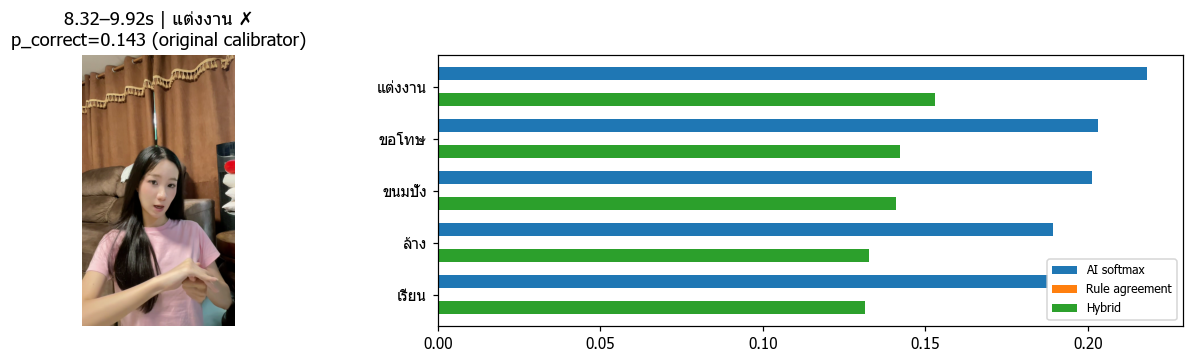

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "low", "relation": null, "motion": ["circle"], "hand_observed": {"left": 1.0, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
105,ฉันแอบชอบคุณ.MOV,hybrid030,5,8.320,9.920,1,แต่งงาน,0.463,0.218,0.000,0.153,False,แอบ,✗
106,ฉันแอบชอบคุณ.MOV,hybrid030,5,8.320,9.920,2,ขอโทษ,0.391,0.203,0.000,0.142,False,แอบ,✗
107,ฉันแอบชอบคุณ.MOV,hybrid030,5,8.320,9.920,3,ขนมปัง,0.382,0.201,0.000,0.141,False,แอบ,✗
108,ฉันแอบชอบคุณ.MOV,hybrid030,5,8.320,9.920,4,ล้าง,0.320,0.189,0.000,0.133,False,แอบ,✗
109,ฉันแอบชอบคุณ.MOV,hybrid030,5,8.320,9.920,5,เรียน,0.312,0.188,0.000,0.131,False,แอบ,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

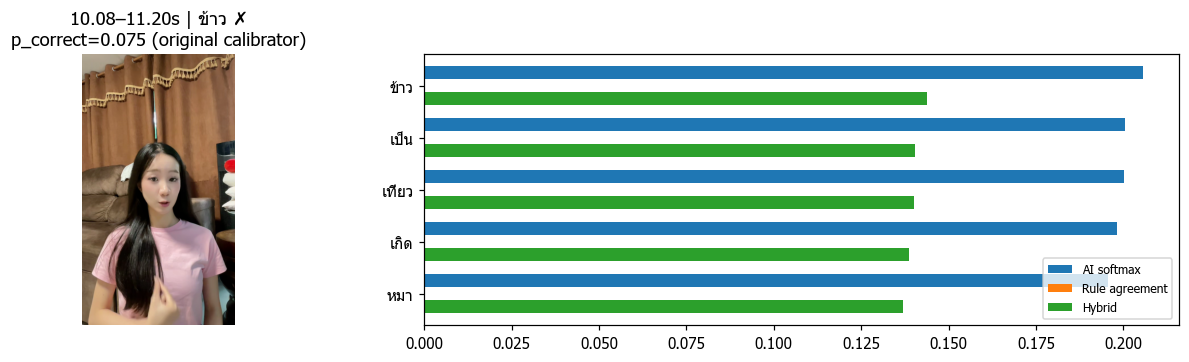

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "chest", "relation": null, "motion": ["circle", "down"], "hand_observed": {"left": 0.714, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
110,ฉันแอบชอบคุณ.MOV,hybrid030,6,10.080,11.200,1,ข้าว,0.452,0.206,0.000,0.144,False,ชอบ,✗
111,ฉันแอบชอบคุณ.MOV,hybrid030,6,10.080,11.200,2,เป็น,0.428,0.200,0.000,0.140,False,ชอบ,✗
112,ฉันแอบชอบคุณ.MOV,hybrid030,6,10.080,11.200,3,เที่ยว,0.427,0.200,0.000,0.140,False,ชอบ,✗
113,ฉันแอบชอบคุณ.MOV,hybrid030,6,10.080,11.200,4,เกิด,0.416,0.198,0.000,0.139,False,ชอบ,✗
114,ฉันแอบชอบคุณ.MOV,hybrid030,6,10.080,11.200,5,หมา,0.403,0.196,0.000,0.137,False,ชอบ,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

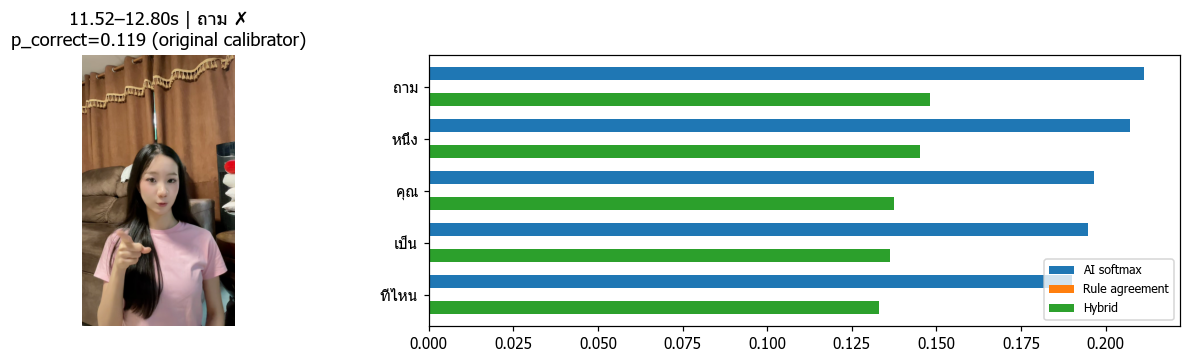

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "chest", "relation": null, "motion": ["circle"], "hand_observed": {"left": 0.531, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
115,ฉันแอบชอบคุณ.MOV,hybrid030,7,11.520,12.800,1,ถาม,0.682,0.211,0.000,0.148,False,คุณ,✗
116,ฉันแอบชอบคุณ.MOV,hybrid030,7,11.520,12.800,2,หนึ่ง,0.662,0.207,0.000,0.145,False,คุณ,✗
117,ฉันแอบชอบคุณ.MOV,hybrid030,7,11.520,12.800,3,คุณ,0.609,0.196,0.000,0.138,False,คุณ,✔
118,ฉันแอบชอบคุณ.MOV,hybrid030,7,11.520,12.800,4,เป็น,0.601,0.195,0.000,0.136,False,คุณ,✗
119,ฉันแอบชอบคุณ.MOV,hybrid030,7,11.520,12.800,5,ที่ไหน,0.575,0.190,0.000,0.133,False,คุณ,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

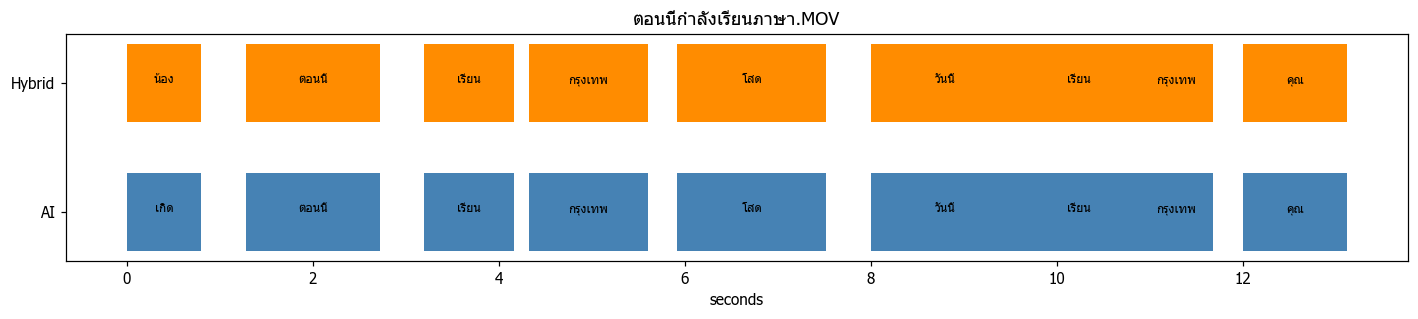

**Timeline:** ตรวจว่าจำนวนและขอบเขตช่วงเปลี่ยนหรือไม่ เพราะ pipeline มี postprocessing หลัง fusion; ความต่างจึงไม่ได้จำกัดอยู่ที่อันดับคำเสมอ

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

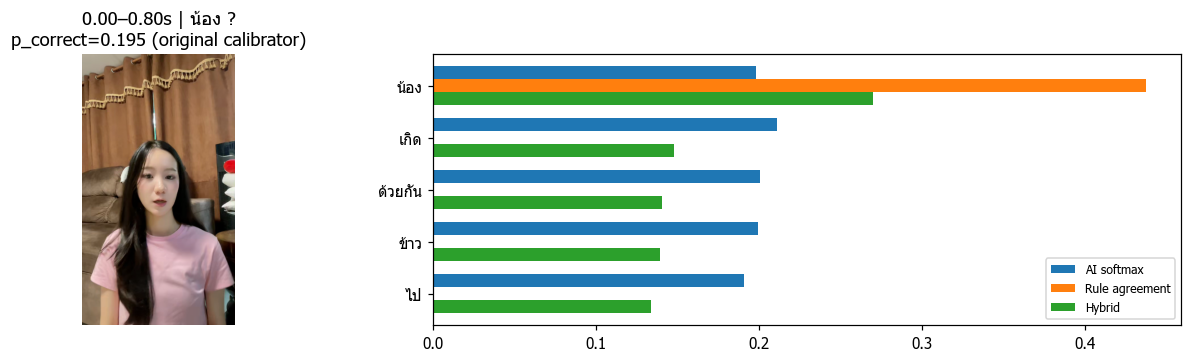

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 1, "location_zone": "face", "relation": null, "motion": [], "hand_observed": {"left": 0.0, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
205,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,0,0.000,0.800,1,น้อง,0.310,0.198,0.438,0.270,True,None,?
206,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,0,0.000,0.800,2,เกิด,0.375,0.211,0.000,0.148,False,None,?
207,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,0,0.000,0.800,3,ด้วยกัน,0.322,0.200,0.000,0.140,False,None,?
208,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,0,0.000,0.800,4,ข้าว,0.316,0.199,0.000,0.139,False,None,?
209,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,0,0.000,0.800,5,ไป,0.274,0.191,0.000,0.134,False,None,?


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

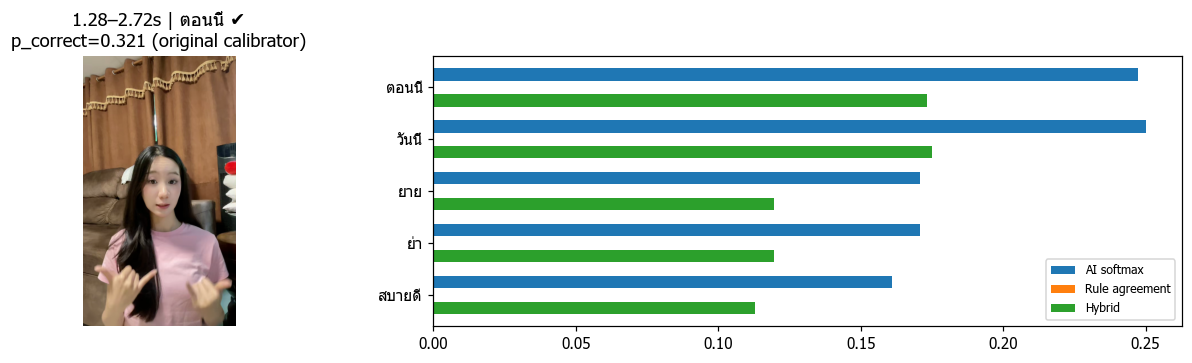

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "chest", "relation": null, "motion": ["circle", "down"], "hand_observed": {"left": 0.556, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
210,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,1,1.280,2.720,1,ตอนนี้,0.812,0.247,0.000,0.173,False,ตอนนี้,✔
211,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,1,1.280,2.720,2,วันนี้,0.822,0.250,0.000,0.175,False,ตอนนี้,✗
212,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,1,1.280,2.720,3,ยาย,0.441,0.171,0.000,0.120,False,ตอนนี้,✗
213,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,1,1.280,2.720,4,ย่า,0.440,0.171,0.000,0.120,False,ตอนนี้,✗
214,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,1,1.280,2.720,5,สบายดี,0.382,0.161,0.000,0.113,False,ตอนนี้,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

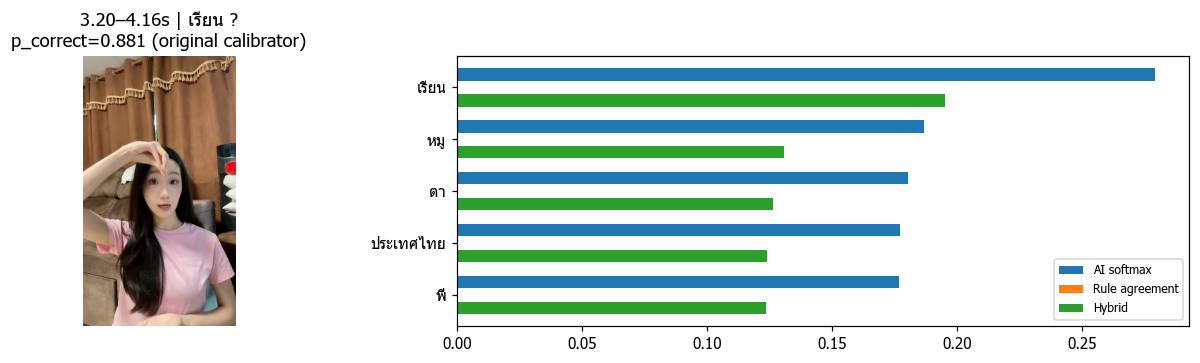

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "chest", "relation": null, "motion": ["circle"], "hand_observed": {"left": 1.0, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
215,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,2,3.200,4.160,1,เรียน,0.789,0.279,0.000,0.195,False,None,?
216,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,2,3.200,4.160,2,หมู,0.387,0.187,0.000,0.131,True,None,?
217,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,2,3.200,4.160,3,ตา,0.353,0.180,0.000,0.126,True,None,?
218,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,2,3.200,4.160,4,ประเทศไทย,0.334,0.177,0.000,0.124,False,None,?
219,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,2,3.200,4.160,5,พี่,0.332,0.177,0.000,0.124,True,None,?


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

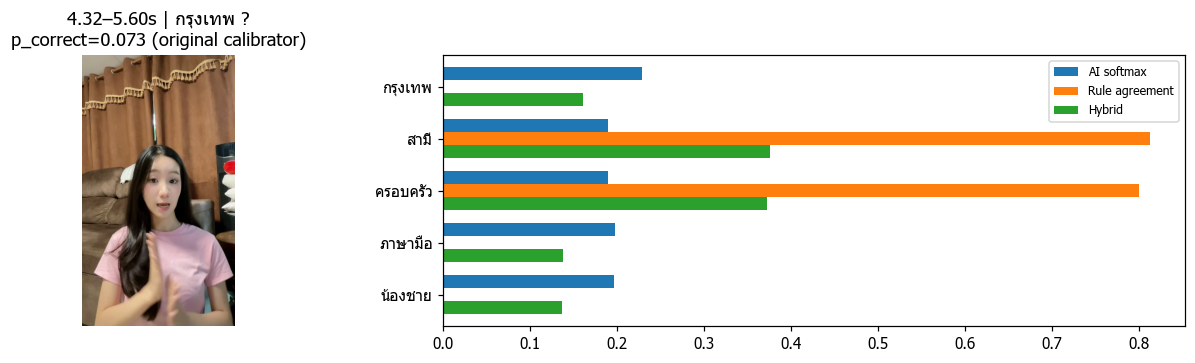

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "chest", "relation": null, "motion": ["circle"], "hand_observed": {"left": 1.0, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
220,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,3,4.320,5.600,1,กรุงเทพ,0.523,0.229,0.000,0.160,False,None,?
221,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,3,4.320,5.600,2,สามี,0.333,0.189,0.812,0.376,True,None,?
222,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,3,4.320,5.600,3,ครอบครัว,0.332,0.189,0.800,0.372,True,None,?
223,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,3,4.320,5.600,4,ภาษามือ,0.374,0.197,0.000,0.138,False,None,?
224,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,3,4.320,5.600,5,น้องชาย,0.367,0.196,0.000,0.137,True,None,?


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

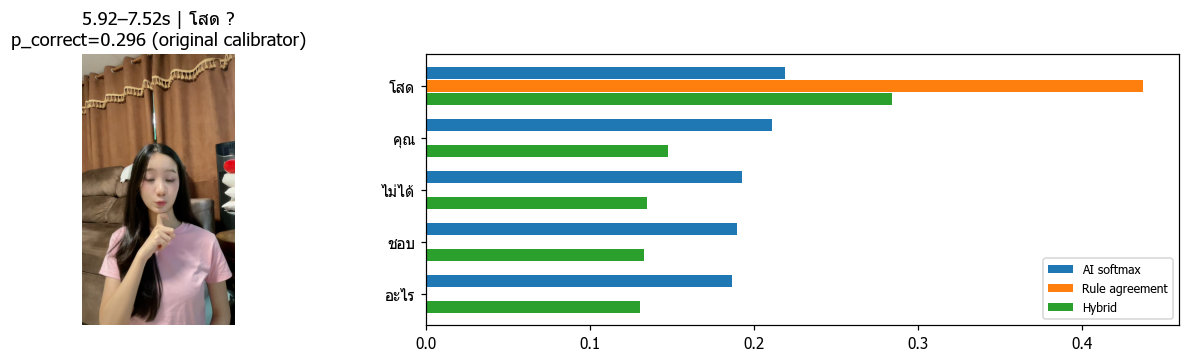

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 1, "location_zone": "face", "relation": null, "motion": ["circle", "up"], "hand_observed": {"left": 0.175, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
225,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,4,5.920,7.520,1,โสด,0.614,0.219,0.438,0.284,True,None,?
226,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,4,5.920,7.520,2,คุณ,0.580,0.211,0.000,0.148,False,None,?
227,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,4,5.920,7.520,3,ไม่ได้,0.489,0.193,0.000,0.135,False,None,?
228,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,4,5.920,7.520,4,ชอบ,0.474,0.190,0.000,0.133,False,None,?
229,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,4,5.920,7.520,5,อะไร,0.454,0.186,0.000,0.130,False,None,?


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

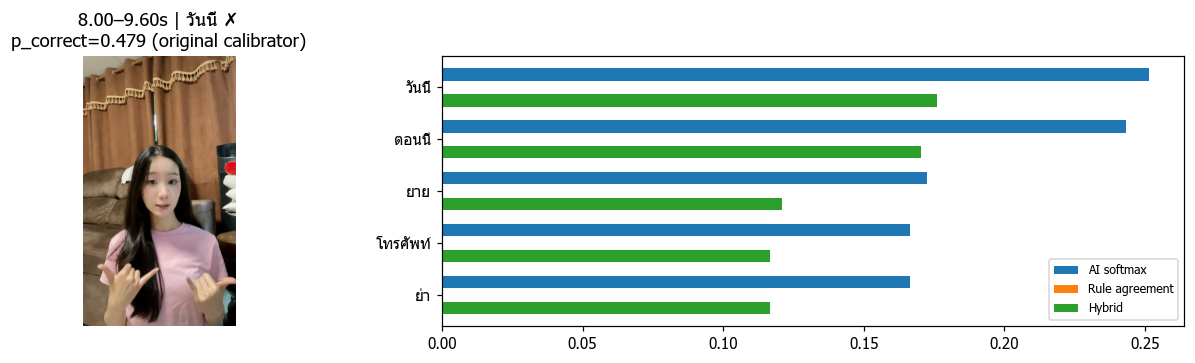

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "chest", "relation": null, "motion": ["circle", "down"], "hand_observed": {"left": 0.625, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
230,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,5,8.000,9.600,1,วันนี้,0.862,0.252,0.000,0.176,False,กำลัง,✗
231,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,5,8.000,9.600,2,ตอนนี้,0.829,0.243,0.000,0.170,False,กำลัง,✗
232,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,5,8.000,9.600,3,ยาย,0.486,0.173,0.000,0.121,False,กำลัง,✗
233,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,5,8.000,9.600,4,โทรศัพท์,0.450,0.166,0.000,0.116,False,กำลัง,✗
234,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,5,8.000,9.600,5,ย่า,0.450,0.166,0.000,0.116,False,กำลัง,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

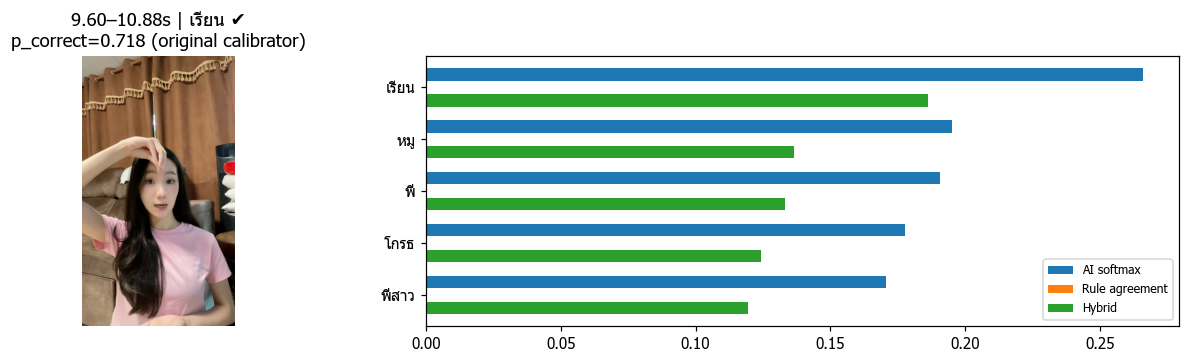

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "chest", "relation": null, "motion": ["circle"], "hand_observed": {"left": 1.0, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
235,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,6,9.600,10.880,1,เรียน,0.773,0.266,0.000,0.186,False,เรียน,✔
236,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,6,9.600,10.880,2,หมู,0.462,0.195,0.000,0.136,True,เรียน,✗
237,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,6,9.600,10.880,3,พี่,0.439,0.190,0.000,0.133,True,เรียน,✗
238,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,6,9.600,10.880,4,โกรธ,0.369,0.178,0.000,0.124,False,เรียน,✗
239,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,6,9.600,10.880,5,พี่สาว,0.329,0.171,0.000,0.120,False,เรียน,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

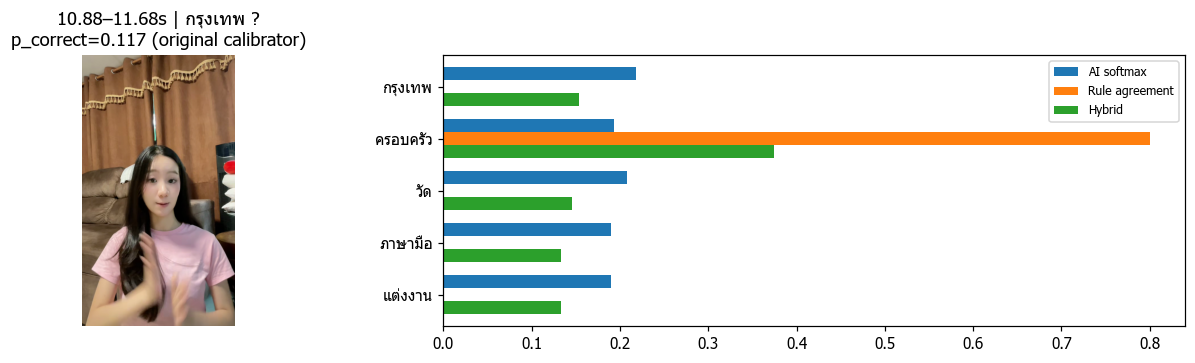

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "chest", "relation": null, "motion": ["circle"], "hand_observed": {"left": 1.0, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
240,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,7,10.880,11.680,1,กรุงเทพ,0.470,0.219,0.000,0.153,False,None,?
241,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,7,10.880,11.680,2,ครอบครัว,0.344,0.193,0.800,0.375,True,None,?
242,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,7,10.880,11.680,3,วัด,0.421,0.208,0.000,0.146,False,None,?
243,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,7,10.880,11.680,4,ภาษามือ,0.331,0.190,0.000,0.133,False,None,?
244,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,7,10.880,11.680,5,แต่งงาน,0.329,0.190,0.000,0.133,False,None,?


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

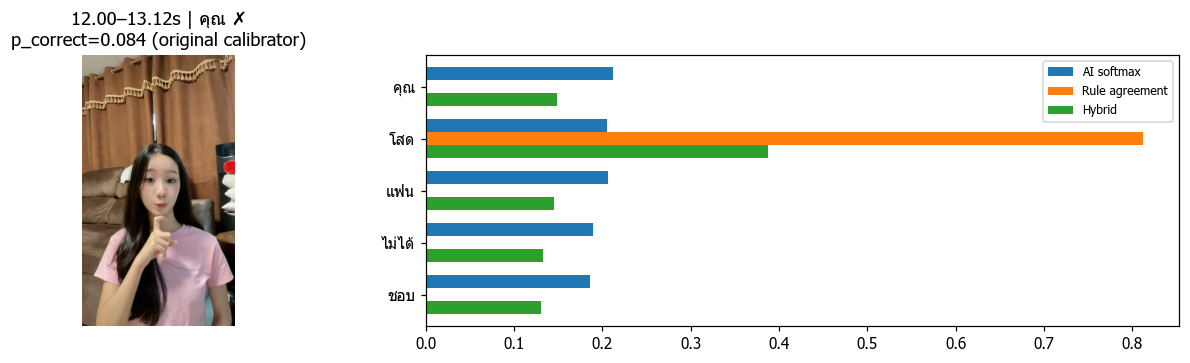

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 1, "location_zone": "chest", "relation": null, "motion": ["circle", "up"], "hand_observed": {"left": 0.286, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
245,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,8,12.000,13.120,1,คุณ,0.551,0.212,0.000,0.148,False,ภาษา,✗
246,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,8,12.000,13.120,2,โสด,0.524,0.206,0.812,0.388,True,ภาษา,✗
247,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,8,12.000,13.120,3,แฟน,0.528,0.207,0.000,0.145,False,ภาษา,✗
248,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,8,12.000,13.120,4,ไม่ได้,0.442,0.190,0.000,0.133,False,ภาษา,✗
249,ตอนนี้กำลังเรียนภาษา.MOV,hybrid030,8,12.000,13.120,5,ชอบ,0.426,0.186,0.000,0.131,False,ภาษา,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

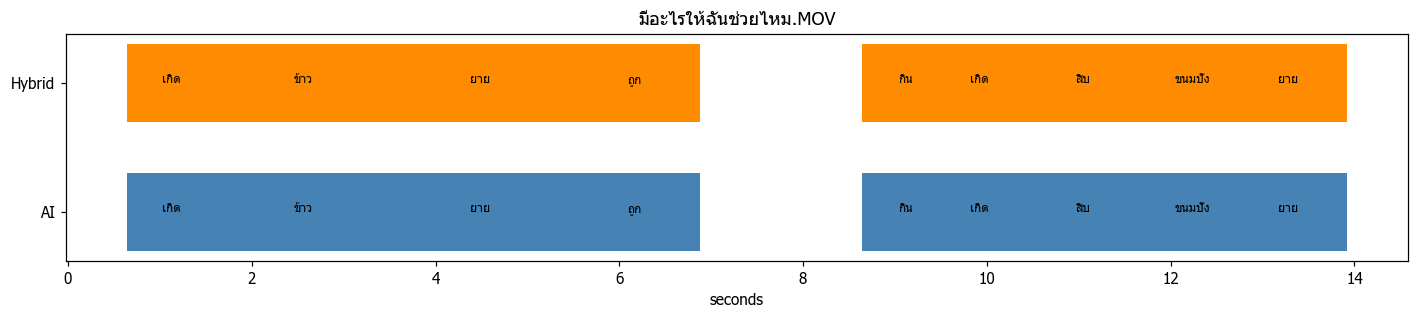

**Timeline:** ตรวจว่าจำนวนและขอบเขตช่วงเปลี่ยนหรือไม่ เพราะ pipeline มี postprocessing หลัง fusion; ความต่างจึงไม่ได้จำกัดอยู่ที่อันดับคำเสมอ

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

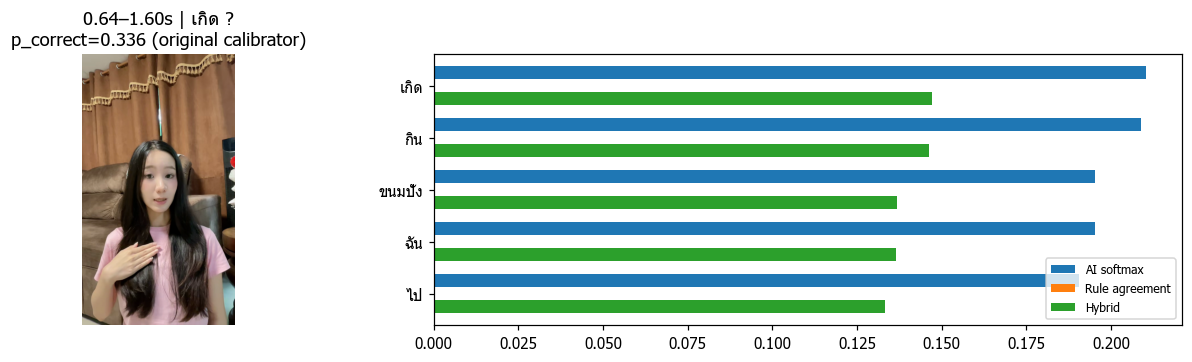

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "low", "relation": null, "motion": ["circle", "down"], "hand_observed": {"left": 0.792, "right": 0.833}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
250,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,0,0.640,1.600,1,เกิด,0.596,0.210,0.000,0.147,False,None,?
251,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,0,0.640,1.600,2,กิน,0.589,0.209,0.000,0.146,False,None,?
252,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,0,0.640,1.600,3,ขนมปัง,0.522,0.195,0.000,0.137,False,None,?
253,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,0,0.640,1.600,4,ฉัน,0.521,0.195,0.000,0.137,False,None,?
254,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,0,0.640,1.600,5,ไป,0.497,0.190,0.000,0.133,False,None,?


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

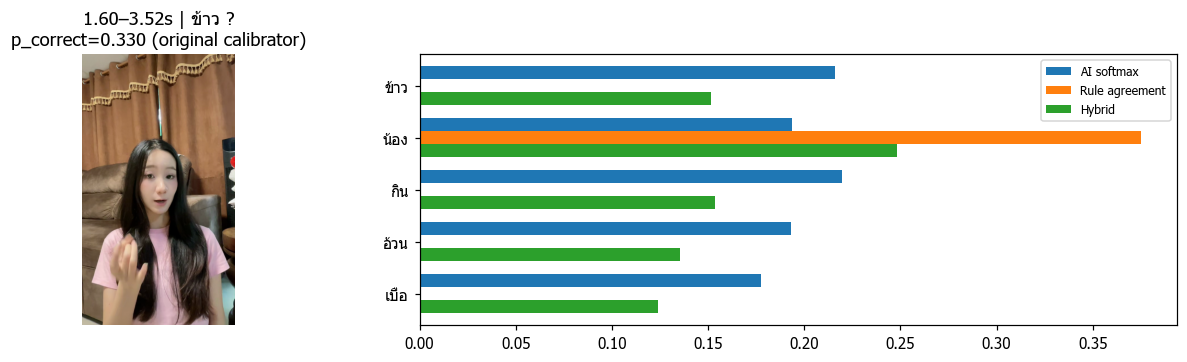

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "chest", "relation": null, "motion": ["circle", "up"], "hand_observed": {"left": 0.604, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
255,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,1,1.600,3.520,1,ข้าว,0.567,0.216,0.000,0.151,False,None,?
256,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,1,1.600,3.520,2,น้อง,0.457,0.194,0.375,0.248,True,None,?
257,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,1,1.600,3.520,3,กิน,0.584,0.220,0.000,0.154,False,None,?
258,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,1,1.600,3.520,4,อ้วน,0.455,0.193,0.000,0.135,False,None,?
259,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,1,1.600,3.520,5,เบื่อ,0.369,0.177,0.000,0.124,False,None,?


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

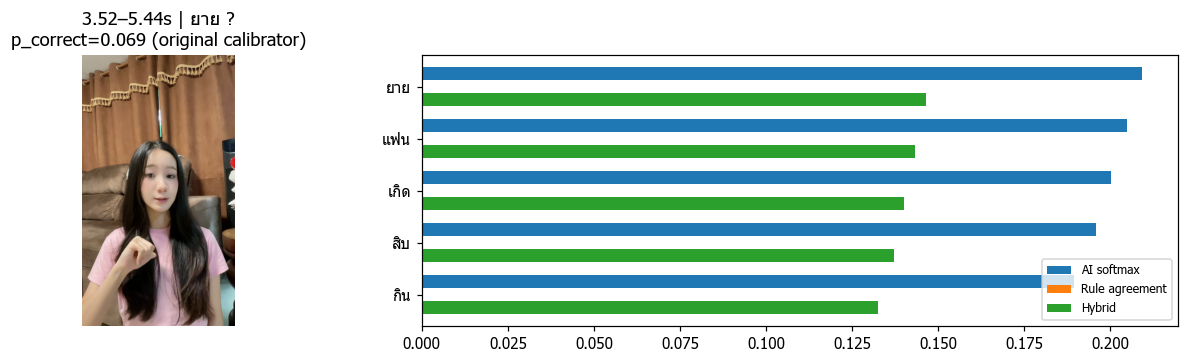

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 1, "location_zone": "chest", "relation": null, "motion": ["circle", "down"], "hand_observed": {"left": 0.292, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
260,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,2,3.520,5.440,1,ยาย,0.527,0.209,0.000,0.146,False,None,?
261,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,2,3.520,5.440,2,แฟน,0.505,0.205,0.000,0.143,False,None,?
262,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,2,3.520,5.440,3,เกิด,0.483,0.200,0.000,0.140,False,None,?
263,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,2,3.520,5.440,4,สิบ,0.462,0.196,0.000,0.137,False,None,?
264,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,2,3.520,5.440,5,กิน,0.428,0.190,0.000,0.133,False,None,?


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

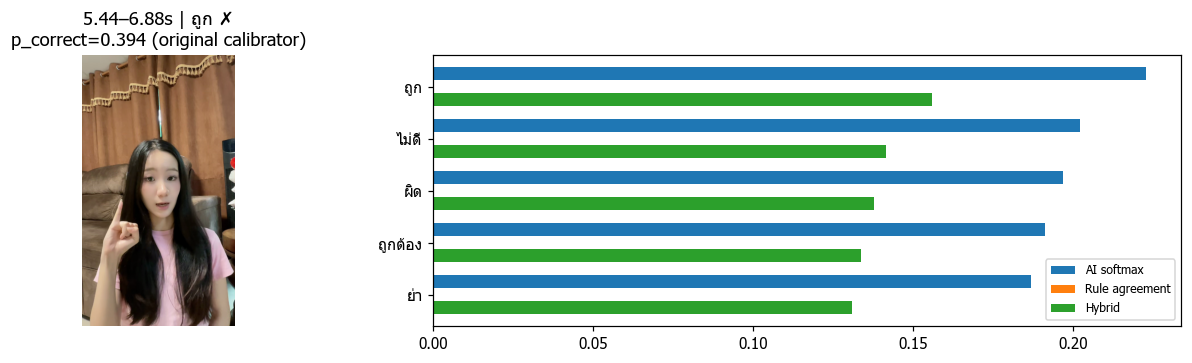

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "chest", "relation": null, "motion": ["circle", "up"], "hand_observed": {"left": 0.694, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
265,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,3,5.440,6.880,1,ถูก,0.673,0.223,0.000,0.156,False,มี,✗
266,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,3,5.440,6.880,2,ไม่ดี,0.577,0.202,0.000,0.142,False,มี,✗
267,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,3,5.440,6.880,3,ผิด,0.549,0.197,0.000,0.138,False,มี,✗
268,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,3,5.440,6.880,4,ถูกต้อง,0.521,0.191,0.000,0.134,False,มี,✗
269,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,3,5.440,6.880,5,ย่า,0.497,0.187,0.000,0.131,False,มี,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

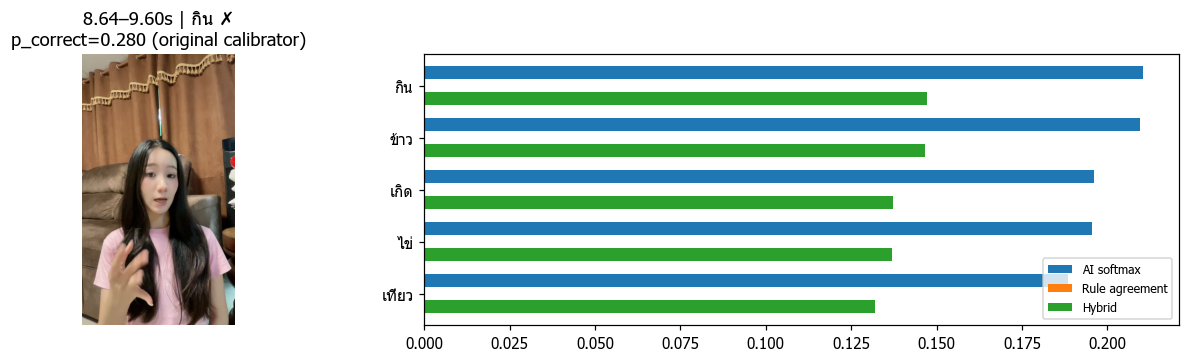

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 1, "location_zone": "face", "relation": null, "motion": ["circle", "down"], "hand_observed": {"left": 0.167, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
270,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,4,8.640,9.600,1,กิน,0.538,0.210,0.000,0.147,False,อะไร,✗
271,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,4,8.640,9.600,2,ข้าว,0.535,0.210,0.000,0.147,False,อะไร,✗
272,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,4,8.640,9.600,3,เกิด,0.468,0.196,0.000,0.137,False,อะไร,✗
273,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,4,8.640,9.600,4,ไข่,0.465,0.195,0.000,0.137,False,อะไร,✗
274,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,4,8.640,9.600,5,เที่ยว,0.430,0.189,0.000,0.132,False,อะไร,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

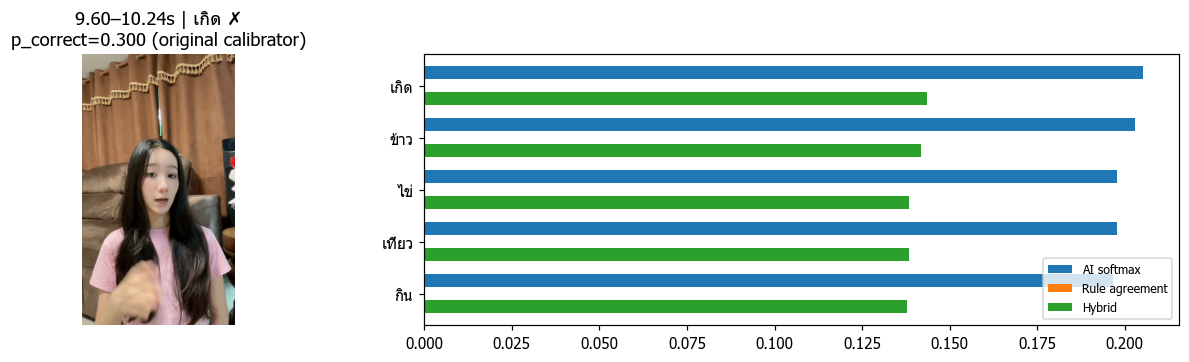

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "low", "relation": null, "motion": ["circle"], "hand_observed": {"left": 1.0, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
275,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,5,9.600,10.240,1,เกิด,0.536,0.205,0.000,0.144,False,ให้,✗
276,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,5,9.600,10.240,2,ข้าว,0.525,0.203,0.000,0.142,False,ให้,✗
277,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,5,9.600,10.240,3,ไข่,0.500,0.198,0.000,0.138,False,ให้,✗
278,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,5,9.600,10.240,4,เที่ยว,0.500,0.198,0.000,0.138,False,ให้,✗
279,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,5,9.600,10.240,5,กิน,0.495,0.197,0.000,0.138,False,ให้,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

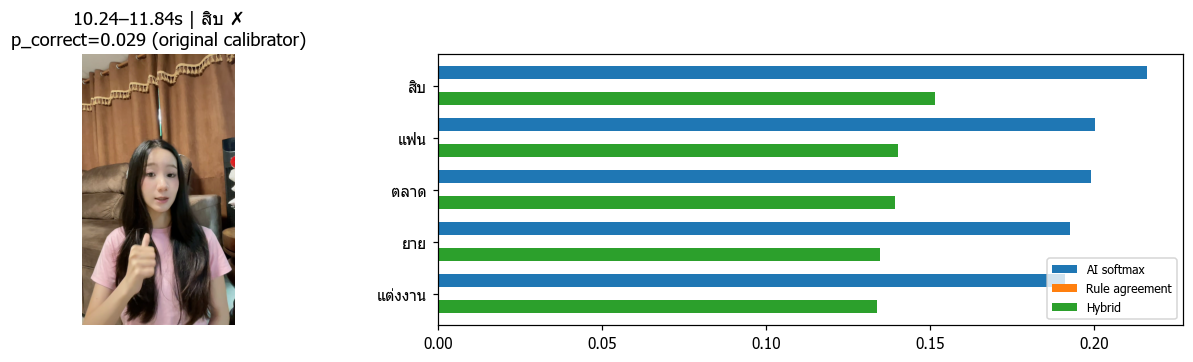

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "low", "relation": null, "motion": ["circle"], "hand_observed": {"left": 1.0, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
280,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,6,10.240,11.840,1,สิบ,0.498,0.216,0.000,0.152,False,ฉัน,✗
281,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,6,10.240,11.840,2,แฟน,0.421,0.200,0.000,0.140,False,ฉัน,✗
282,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,6,10.240,11.840,3,ตลาด,0.416,0.199,0.000,0.140,False,ฉัน,✗
283,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,6,10.240,11.840,4,ยาย,0.383,0.193,0.000,0.135,False,ฉัน,✗
284,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,6,10.240,11.840,5,แต่งงาน,0.376,0.191,0.000,0.134,False,ฉัน,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

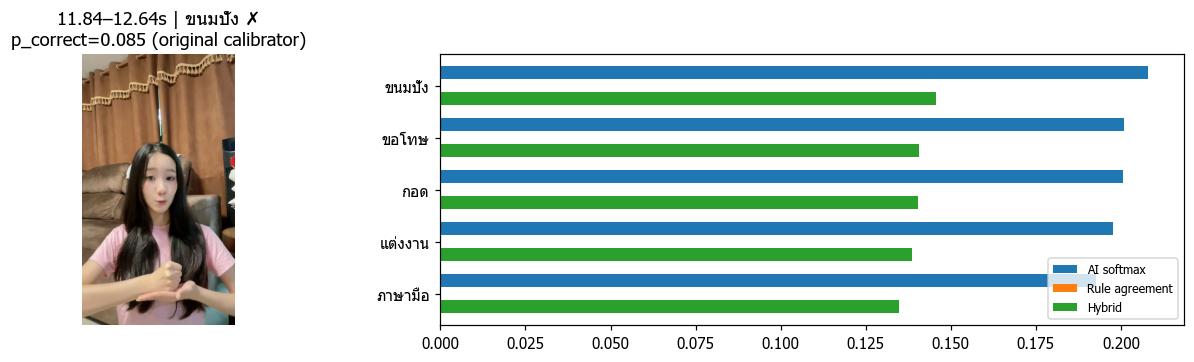

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "low", "relation": null, "motion": ["circle"], "hand_observed": {"left": 1.0, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
285,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,7,11.840,12.640,1,ขนมปัง,0.348,0.208,0.000,0.146,False,ช่วย,✗
286,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,7,11.840,12.640,2,ขอโทษ,0.312,0.201,0.000,0.141,False,ช่วย,✗
287,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,7,11.840,12.640,3,กอด,0.311,0.200,0.000,0.140,False,ช่วย,✗
288,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,7,11.840,12.640,4,แต่งงาน,0.298,0.198,0.000,0.138,False,ช่วย,✗
289,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,7,11.840,12.640,5,ภาษามือ,0.271,0.193,0.000,0.135,False,ช่วย,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

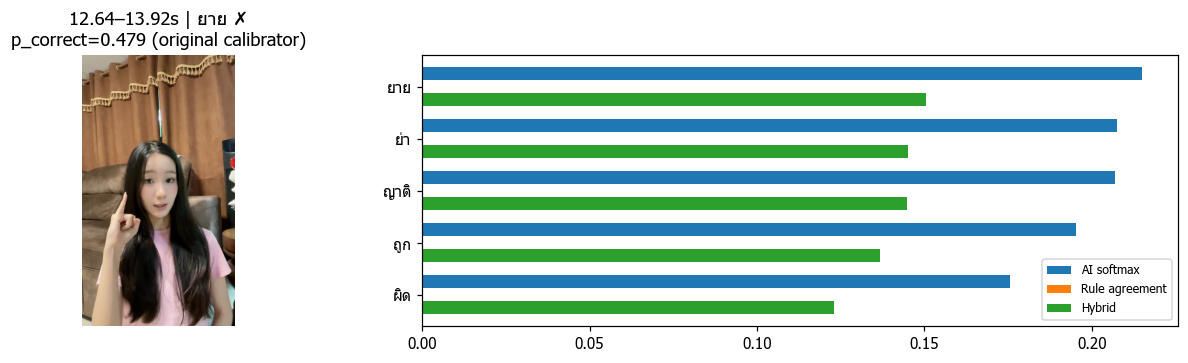

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "chest", "relation": null, "motion": ["up"], "hand_observed": {"left": 0.781, "right": 0.938}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
290,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,8,12.640,13.920,1,ยาย,0.681,0.215,0.000,0.150,False,ไหม,✗
291,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,8,12.640,13.920,2,ย่า,0.645,0.207,0.000,0.145,False,ไหม,✗
292,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,8,12.640,13.920,3,ญาติ,0.644,0.207,0.000,0.145,False,ไหม,✗
293,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,8,12.640,13.920,4,ถูก,0.584,0.195,0.000,0.137,False,ไหม,✗
294,มีอะไรให้ฉันช่วยไหม.MOV,hybrid030,8,12.640,13.920,5,ผิด,0.478,0.176,0.000,0.123,False,ไหม,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

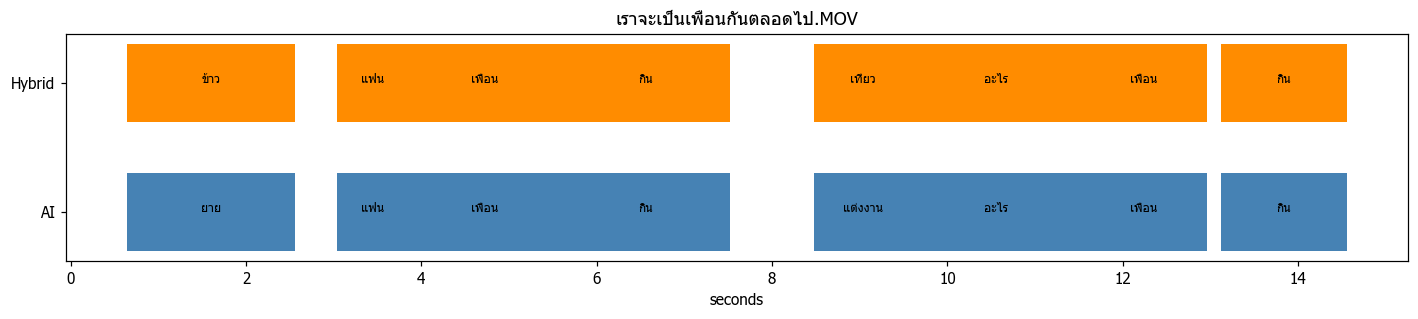

**Timeline:** ตรวจว่าจำนวนและขอบเขตช่วงเปลี่ยนหรือไม่ เพราะ pipeline มี postprocessing หลัง fusion; ความต่างจึงไม่ได้จำกัดอยู่ที่อันดับคำเสมอ

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

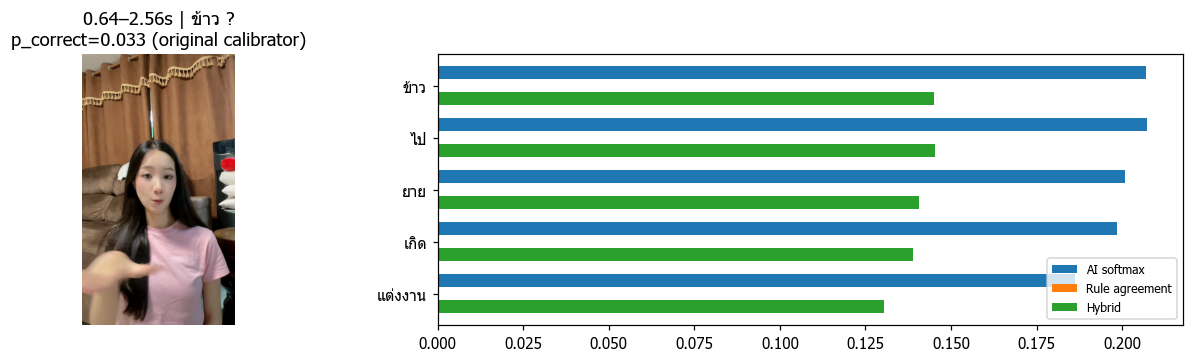

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 1, "location_zone": "chest", "relation": null, "motion": ["circle", "down"], "hand_observed": {"left": 0.417, "right": 0.917}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
380,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,0,0.640,2.560,1,ข้าว,0.516,0.207,0.000,0.145,False,None,?
381,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,0,0.640,2.560,2,ไป,0.518,0.207,0.000,0.145,False,None,?
382,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,0,0.640,2.560,3,ยาย,0.486,0.201,0.000,0.140,False,None,?
383,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,0,0.640,2.560,4,เกิด,0.474,0.198,0.000,0.139,False,None,?
384,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,0,0.640,2.560,5,แต่งงาน,0.411,0.186,0.000,0.130,False,None,?


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

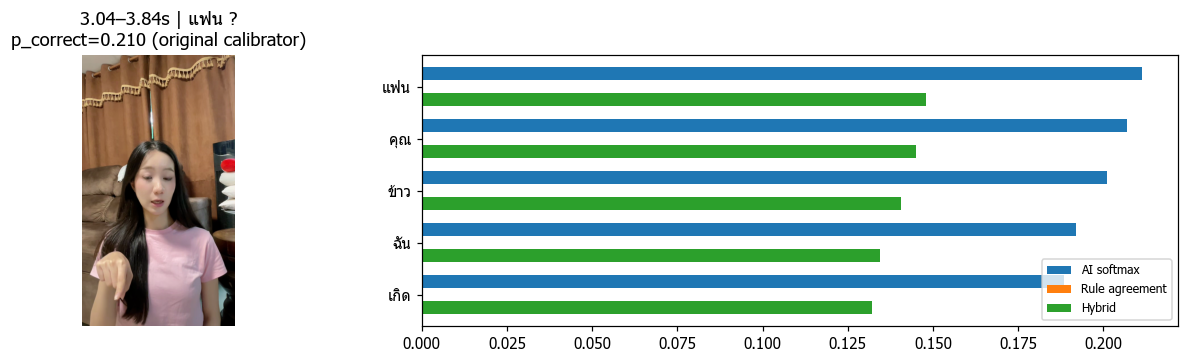

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 1, "location_zone": "face", "relation": null, "motion": ["down"], "hand_observed": {"left": 0.0, "right": 0.75}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
385,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,1,3.040,3.840,1,แฟน,0.496,0.211,0.000,0.148,False,None,?
386,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,1,3.040,3.840,2,คุณ,0.476,0.207,0.000,0.145,False,None,?
387,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,1,3.040,3.840,3,ข้าว,0.446,0.201,0.000,0.141,False,None,?
388,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,1,3.040,3.840,4,ฉัน,0.400,0.192,0.000,0.134,False,None,?
389,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,1,3.040,3.840,5,เกิด,0.382,0.189,0.000,0.132,False,None,?


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

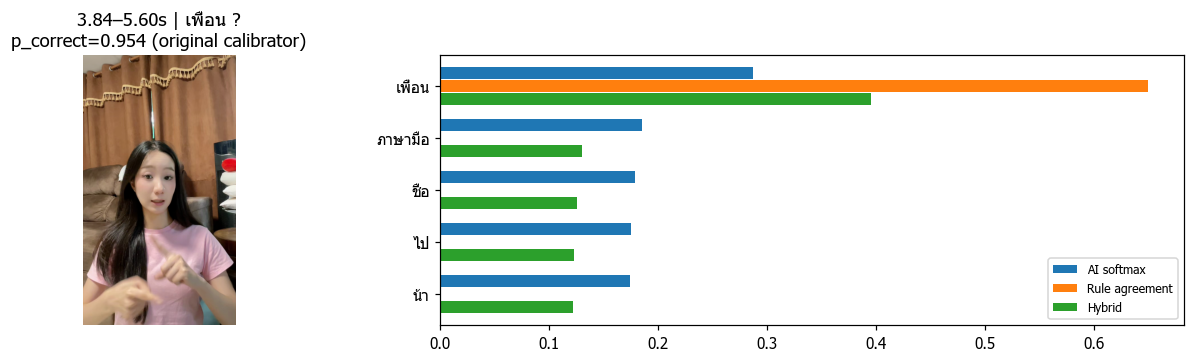

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "chest", "relation": null, "motion": ["circle", "down"], "hand_observed": {"left": 0.932, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
390,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,2,3.840,5.600,1,เพื่อน,0.824,0.287,0.650,0.396,True,None,?
391,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,2,3.840,5.600,2,ภาษามือ,0.388,0.185,0.000,0.130,False,None,?
392,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,2,3.840,5.600,3,ชื่อ,0.354,0.179,0.000,0.125,False,None,?
393,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,2,3.840,5.600,4,ไป,0.332,0.175,0.000,0.122,False,None,?
394,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,2,3.840,5.600,5,น้า,0.326,0.174,0.000,0.122,False,None,?


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

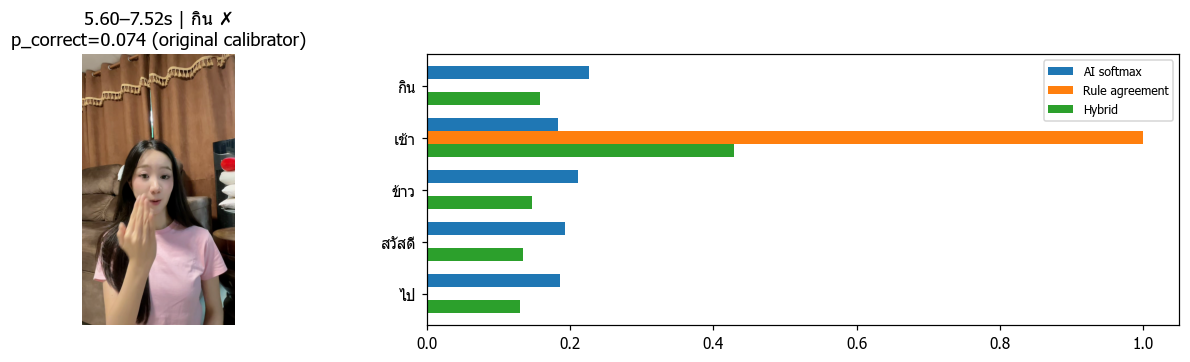

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "chest", "relation": null, "motion": ["circle", "up"], "hand_observed": {"left": 0.771, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
395,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,3,5.600,7.520,1,กิน,0.673,0.226,0.000,0.159,False,เรา,✗
396,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,3,5.600,7.520,2,เช้า,0.463,0.184,1.000,0.428,True,เรา,✗
397,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,3,5.600,7.520,3,ข้าว,0.600,0.211,0.000,0.148,False,เรา,✗
398,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,3,5.600,7.520,4,สวัสดี,0.511,0.193,0.000,0.135,False,เรา,✗
399,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,3,5.600,7.520,5,ไป,0.479,0.187,0.000,0.131,False,เรา,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

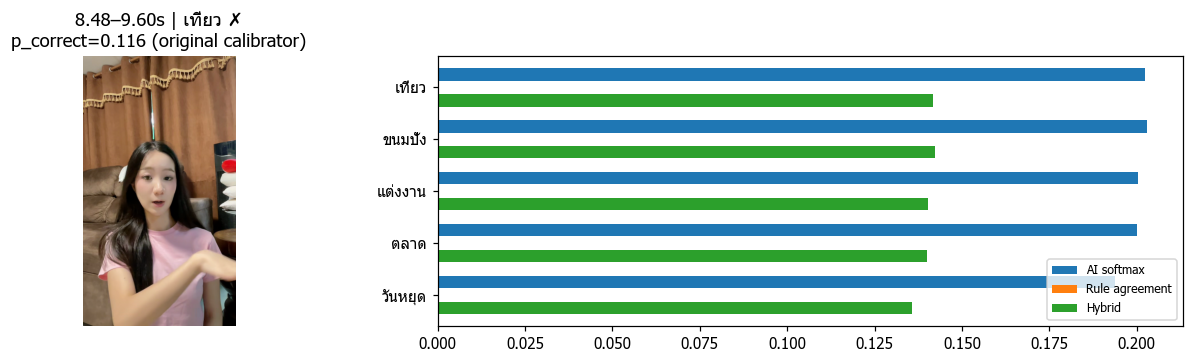

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 1, "location_zone": "chest", "relation": null, "motion": ["circle", "down"], "hand_observed": {"left": 0.5, "right": 0.857}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
400,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,4,8.480,9.600,1,เที่ยว,0.406,0.202,0.000,0.142,False,จะ,✗
401,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,4,8.480,9.600,2,ขนมปัง,0.410,0.203,0.000,0.142,False,จะ,✗
402,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,4,8.480,9.600,3,แต่งงาน,0.397,0.200,0.000,0.140,False,จะ,✗
403,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,4,8.480,9.600,4,ตลาด,0.395,0.200,0.000,0.140,False,จะ,✗
404,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,4,8.480,9.600,5,วันหยุด,0.362,0.194,0.000,0.136,False,จะ,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

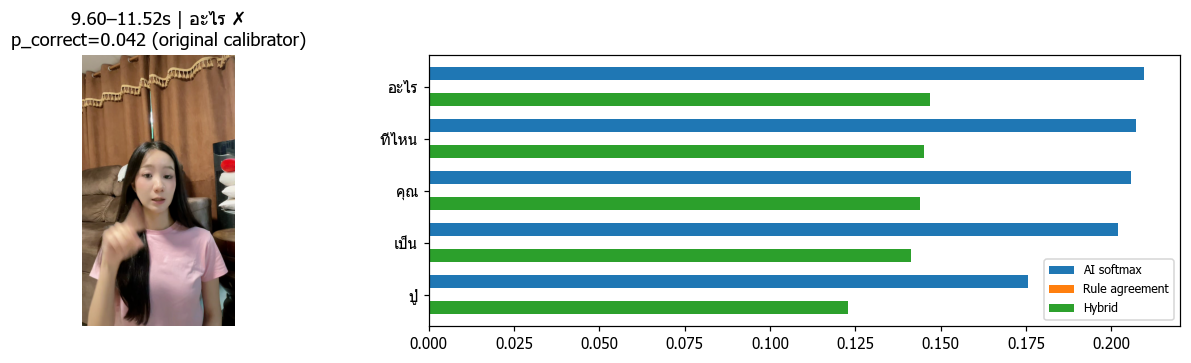

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 1, "location_zone": "face", "relation": null, "motion": ["circle"], "hand_observed": {"left": 0.0, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
405,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,5,9.600,11.520,1,อะไร,0.582,0.210,0.000,0.147,False,เป็นเพื่อน,✗
406,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,5,9.600,11.520,2,ที่ไหน,0.572,0.207,0.000,0.145,False,เป็นเพื่อน,✗
407,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,5,9.600,11.520,3,คุณ,0.563,0.206,0.000,0.144,False,เป็นเพื่อน,✗
408,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,5,9.600,11.520,4,เป็น,0.545,0.202,0.000,0.141,False,เป็นเพื่อน,✗
409,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,5,9.600,11.520,5,ปู่,0.406,0.176,0.000,0.123,False,เป็นเพื่อน,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

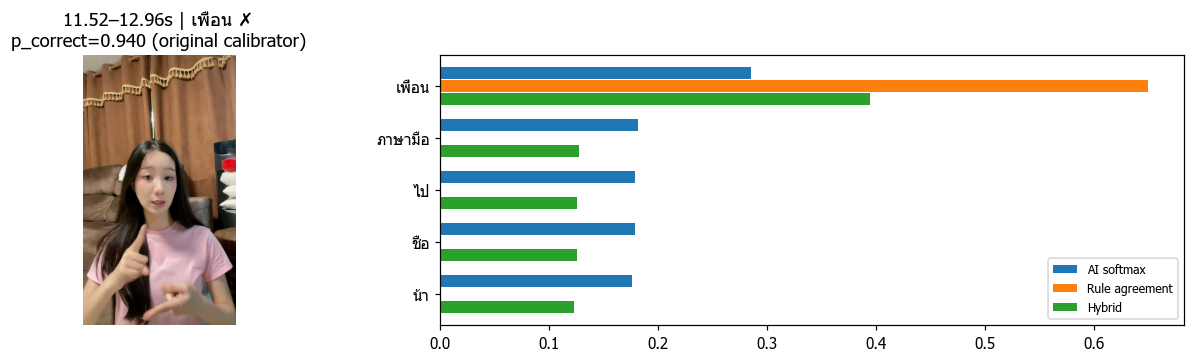

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "chest", "relation": null, "motion": ["circle", "down"], "hand_observed": {"left": 0.722, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
410,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,6,11.520,12.960,1,เพื่อน,0.806,0.285,0.650,0.395,True,กัน,✗
411,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,6,11.520,12.960,2,ภาษามือ,0.352,0.181,0.000,0.127,False,กัน,✗
412,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,6,11.520,12.960,3,ไป,0.339,0.179,0.000,0.125,False,กัน,✗
413,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,6,11.520,12.960,4,ชื่อ,0.339,0.179,0.000,0.125,False,กัน,✗
414,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,6,11.520,12.960,5,น้า,0.322,0.176,0.000,0.123,False,กัน,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

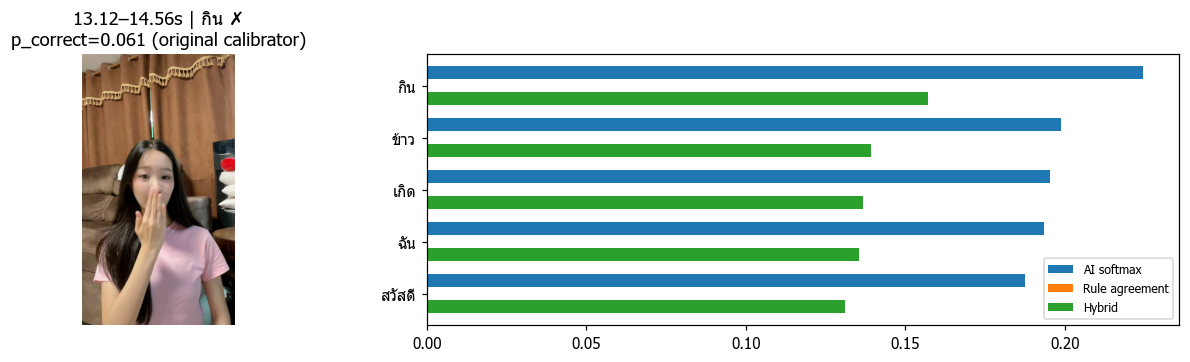

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "chest", "relation": null, "motion": ["circle", "up"], "hand_observed": {"left": 0.778, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
415,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,7,13.120,14.560,1,กิน,0.681,0.225,0.000,0.157,False,ตลอดไป,✗
416,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,7,13.120,14.560,2,ข้าว,0.558,0.199,0.000,0.139,False,ตลอดไป,✗
417,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,7,13.120,14.560,3,เกิด,0.542,0.196,0.000,0.137,False,ตลอดไป,✗
418,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,7,13.120,14.560,4,ฉัน,0.532,0.194,0.000,0.136,False,ตลอดไป,✗
419,เราจะเป็นเพื่อนกันตลอดไป.MOV,hybrid030,7,13.120,14.560,5,สวัสดี,0.500,0.188,0.000,0.131,False,ตลอดไป,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

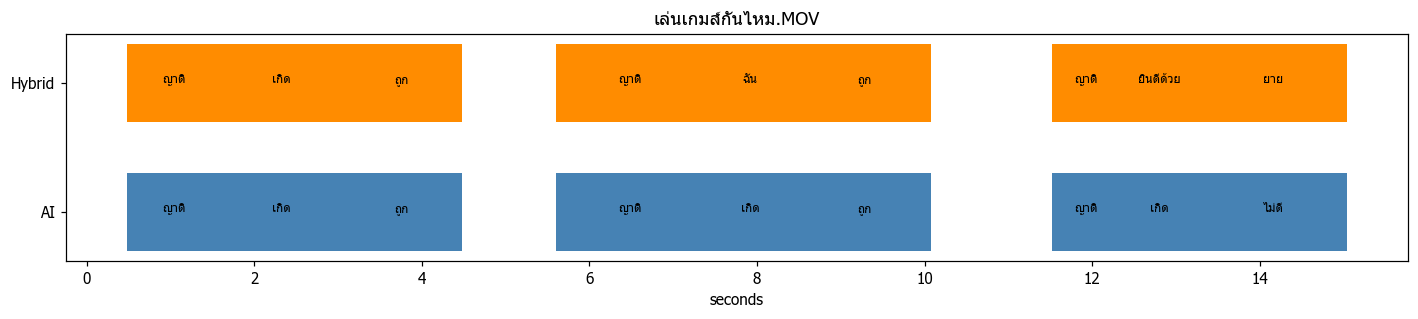

**Timeline:** ตรวจว่าจำนวนและขอบเขตช่วงเปลี่ยนหรือไม่ เพราะ pipeline มี postprocessing หลัง fusion; ความต่างจึงไม่ได้จำกัดอยู่ที่อันดับคำเสมอ

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

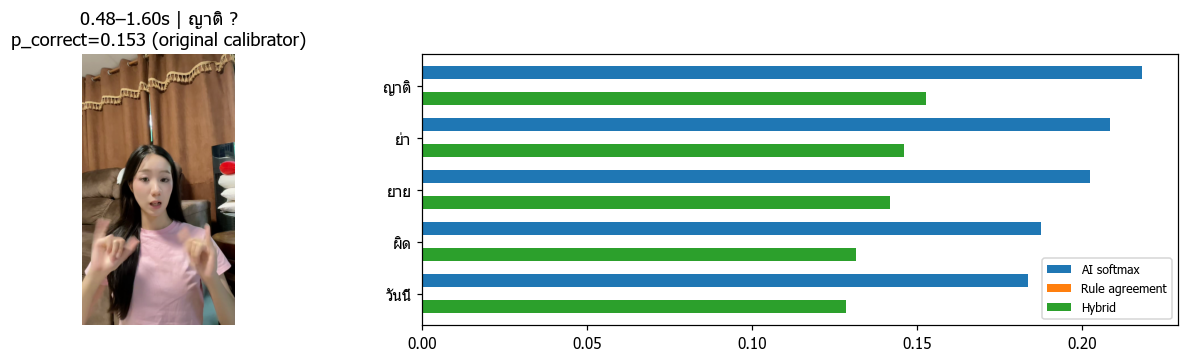

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "chest", "relation": null, "motion": ["circle", "down"], "hand_observed": {"left": 0.786, "right": 0.75}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
420,เล่นเกมส์กันไหม.MOV,hybrid030,0,0.480,1.600,1,ญาติ,0.563,0.218,0.000,0.153,False,None,?
421,เล่นเกมส์กันไหม.MOV,hybrid030,0,0.480,1.600,2,ย่า,0.518,0.208,0.000,0.146,False,None,?
422,เล่นเกมส์กันไหม.MOV,hybrid030,0,0.480,1.600,3,ยาย,0.488,0.202,0.000,0.142,False,None,?
423,เล่นเกมส์กันไหม.MOV,hybrid030,0,0.480,1.600,4,ผิด,0.412,0.188,0.000,0.131,False,None,?
424,เล่นเกมส์กันไหม.MOV,hybrid030,0,0.480,1.600,5,วันนี้,0.391,0.184,0.000,0.128,False,None,?


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

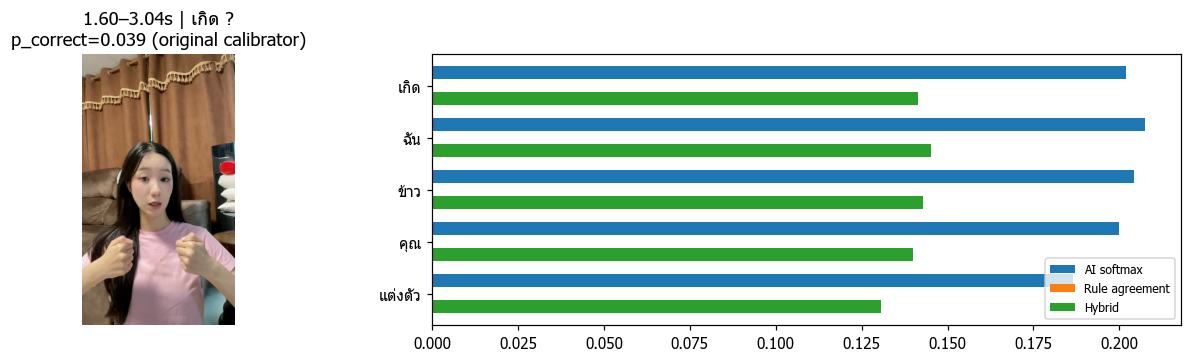

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "chest", "relation": null, "motion": ["circle"], "hand_observed": {"left": 1.0, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
425,เล่นเกมส์กันไหม.MOV,hybrid030,1,1.600,3.040,1,เกิด,0.482,0.202,0.000,0.141,False,None,?
426,เล่นเกมส์กันไหม.MOV,hybrid030,1,1.600,3.040,2,ฉัน,0.510,0.208,0.000,0.145,False,None,?
427,เล่นเกมส์กันไหม.MOV,hybrid030,1,1.600,3.040,3,ข้าว,0.494,0.204,0.000,0.143,False,None,?
428,เล่นเกมส์กันไหม.MOV,hybrid030,1,1.600,3.040,4,คุณ,0.472,0.200,0.000,0.140,False,None,?
429,เล่นเกมส์กันไหม.MOV,hybrid030,1,1.600,3.040,5,แต่งตัว,0.403,0.186,0.000,0.130,False,None,?


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

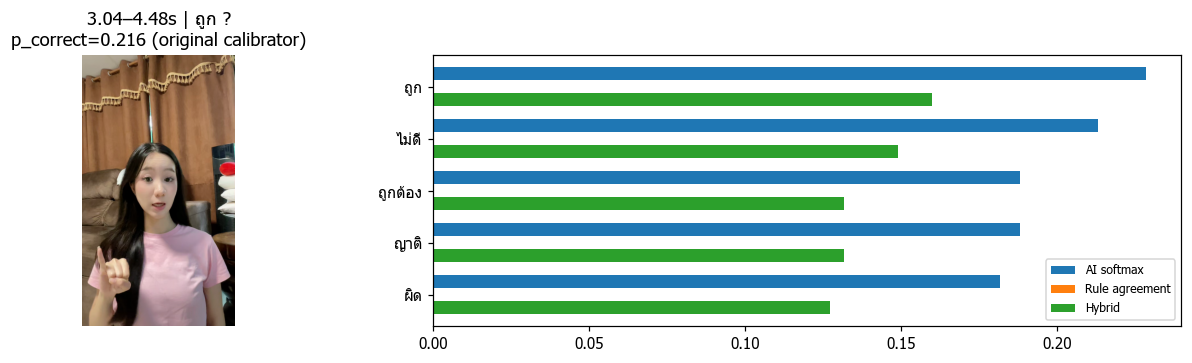

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 1, "location_zone": "chest", "relation": null, "motion": ["circle", "up"], "hand_observed": {"left": 0.389, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
430,เล่นเกมส์กันไหม.MOV,hybrid030,2,3.040,4.480,1,ถูก,0.683,0.229,0.000,0.160,False,None,?
431,เล่นเกมส์กันไหม.MOV,hybrid030,2,3.040,4.480,2,ไม่ดี,0.614,0.213,0.000,0.149,False,None,?
432,เล่นเกมส์กันไหม.MOV,hybrid030,2,3.040,4.480,3,ถูกต้อง,0.489,0.188,0.000,0.132,False,None,?
433,เล่นเกมส์กันไหม.MOV,hybrid030,2,3.040,4.480,4,ญาติ,0.489,0.188,0.000,0.132,False,None,?
434,เล่นเกมส์กันไหม.MOV,hybrid030,2,3.040,4.480,5,ผิด,0.454,0.182,0.000,0.127,False,None,?


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

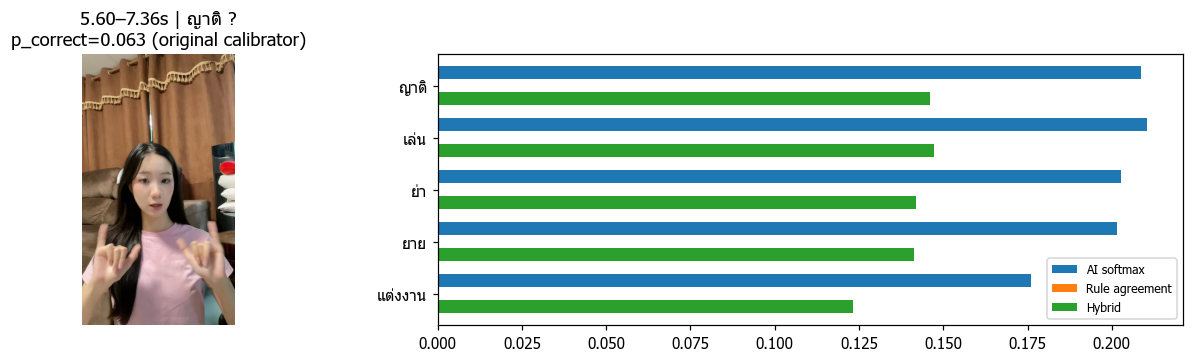

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "chest", "relation": null, "motion": ["circle", "down"], "hand_observed": {"left": 0.886, "right": 0.955}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
435,เล่นเกมส์กันไหม.MOV,hybrid030,3,5.600,7.360,1,ญาติ,0.551,0.209,0.000,0.146,False,None,?
436,เล่นเกมส์กันไหม.MOV,hybrid030,3,5.600,7.360,2,เล่น,0.560,0.211,0.000,0.147,False,None,?
437,เล่นเกมส์กันไหม.MOV,hybrid030,3,5.600,7.360,3,ย่า,0.522,0.203,0.000,0.142,False,None,?
438,เล่นเกมส์กันไหม.MOV,hybrid030,3,5.600,7.360,4,ยาย,0.517,0.202,0.000,0.141,False,None,?
439,เล่นเกมส์กันไหม.MOV,hybrid030,3,5.600,7.360,5,แต่งงาน,0.381,0.176,0.000,0.123,False,None,?


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

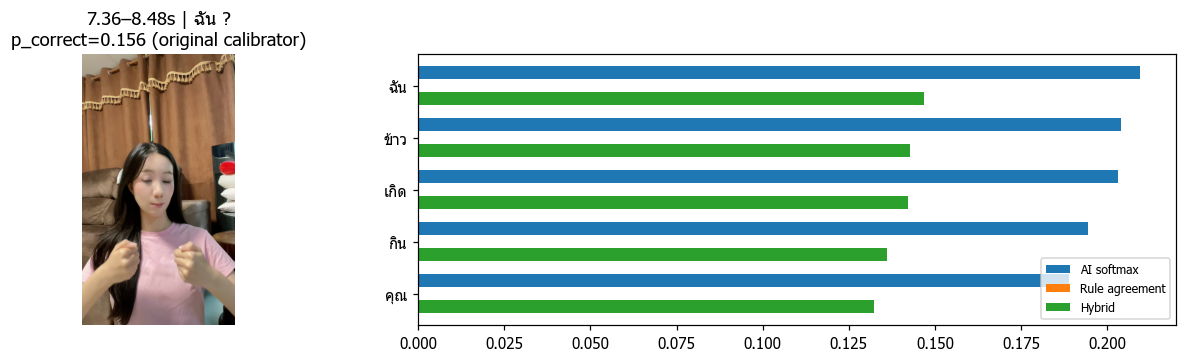

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "chest", "relation": null, "motion": ["circle", "down"], "hand_observed": {"left": 1.0, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
440,เล่นเกมส์กันไหม.MOV,hybrid030,4,7.360,8.480,1,ฉัน,0.598,0.210,0.000,0.147,False,None,?
441,เล่นเกมส์กันไหม.MOV,hybrid030,4,7.360,8.480,2,ข้าว,0.570,0.204,0.000,0.143,False,None,?
442,เล่นเกมส์กันไหม.MOV,hybrid030,4,7.360,8.480,3,เกิด,0.566,0.203,0.000,0.142,False,None,?
443,เล่นเกมส์กันไหม.MOV,hybrid030,4,7.360,8.480,4,กิน,0.522,0.194,0.000,0.136,False,None,?
444,เล่นเกมส์กันไหม.MOV,hybrid030,4,7.360,8.480,5,คุณ,0.494,0.189,0.000,0.132,False,None,?


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

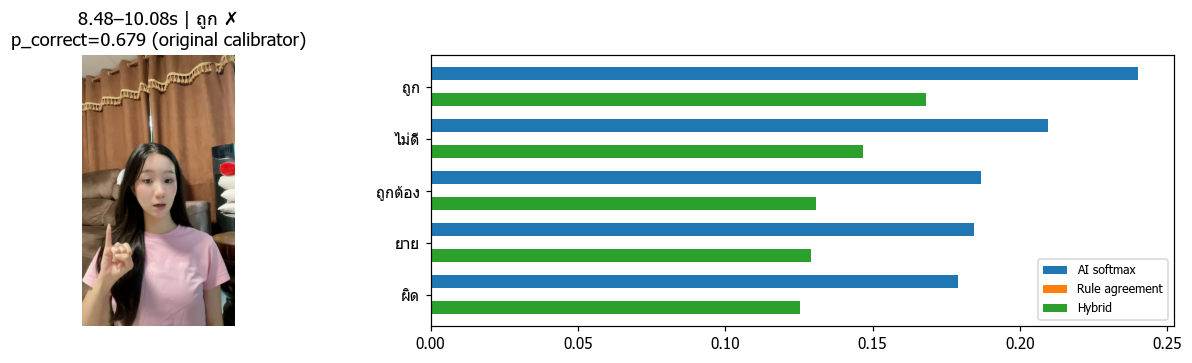

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 1, "location_zone": "face", "relation": null, "motion": ["circle", "up"], "hand_observed": {"left": 0.05, "right": 0.975}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
445,เล่นเกมส์กันไหม.MOV,hybrid030,5,8.480,10.080,1,ถูก,0.726,0.240,0.000,0.168,False,เล่น,✗
446,เล่นเกมส์กันไหม.MOV,hybrid030,5,8.480,10.080,2,ไม่ดี,0.589,0.210,0.000,0.147,False,เล่น,✗
447,เล่นเกมส์กันไหม.MOV,hybrid030,5,8.480,10.080,3,ถูกต้อง,0.475,0.187,0.000,0.131,False,เล่น,✗
448,เล่นเกมส์กันไหม.MOV,hybrid030,5,8.480,10.080,4,ยาย,0.461,0.184,0.000,0.129,False,เล่น,✗
449,เล่นเกมส์กันไหม.MOV,hybrid030,5,8.480,10.080,5,ผิด,0.432,0.179,0.000,0.125,False,เล่น,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

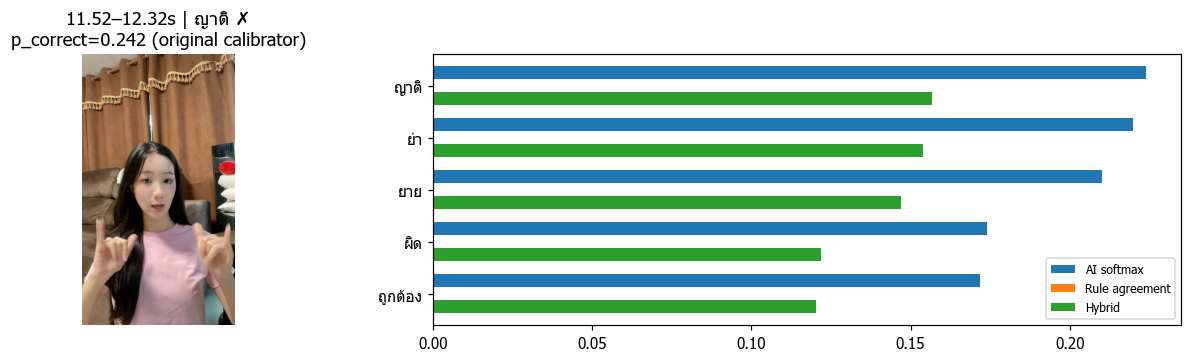

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "chest", "relation": null, "motion": ["circle", "down"], "hand_observed": {"left": 0.8, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
450,เล่นเกมส์กันไหม.MOV,hybrid030,6,11.520,12.320,1,ญาติ,0.624,0.224,0.000,0.157,False,เกมส์,✗
451,เล่นเกมส์กันไหม.MOV,hybrid030,6,11.520,12.320,2,ย่า,0.606,0.220,0.000,0.154,False,เกมส์,✗
452,เล่นเกมส์กันไหม.MOV,hybrid030,6,11.520,12.320,3,ยาย,0.560,0.210,0.000,0.147,False,เกมส์,✗
453,เล่นเกมส์กันไหม.MOV,hybrid030,6,11.520,12.320,4,ผิด,0.372,0.174,0.000,0.122,False,เกมส์,✗
454,เล่นเกมส์กันไหม.MOV,hybrid030,6,11.520,12.320,5,ถูกต้อง,0.360,0.172,0.000,0.120,False,เกมส์,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

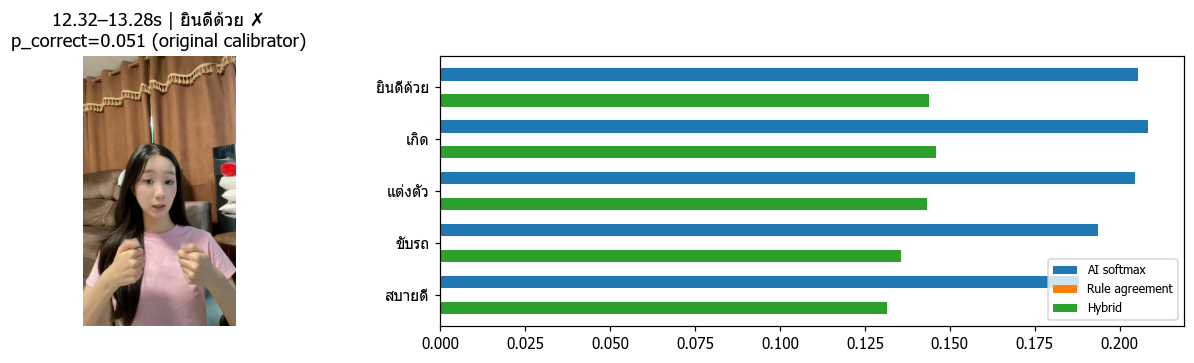

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "chest", "relation": null, "motion": ["circle"], "hand_observed": {"left": 1.0, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
455,เล่นเกมส์กันไหม.MOV,hybrid030,7,12.320,13.280,1,ยินดีด้วย,0.417,0.206,0.000,0.144,False,กัน,✗
456,เล่นเกมส์กันไหม.MOV,hybrid030,7,12.320,13.280,2,เกิด,0.431,0.208,0.000,0.146,False,กัน,✗
457,เล่นเกมส์กันไหม.MOV,hybrid030,7,12.320,13.280,3,แต่งตัว,0.413,0.205,0.000,0.143,False,กัน,✗
458,เล่นเกมส์กันไหม.MOV,hybrid030,7,12.320,13.280,4,ขับรถ,0.357,0.194,0.000,0.136,False,กัน,✗
459,เล่นเกมส์กันไหม.MOV,hybrid030,7,12.320,13.280,5,สบายดี,0.327,0.188,0.000,0.132,False,กัน,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font family 'Leelawadee UI' not found.
findfont: Font famil

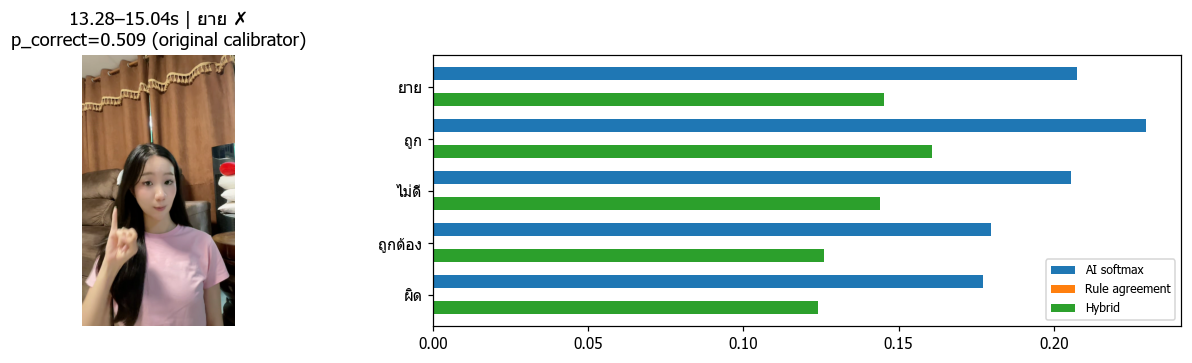

**อ่านภาพ:** เฟรมจริงตรงกลางช่วง ไม่ใช่หลักฐานการเคลื่อนไหวทั้งช่วง; `{"hands": 2, "location_zone": "chest", "relation": null, "motion": ["circle", "up"], "hand_observed": {"left": 0.614, "right": 1.0}}`. Rule score และคะแนนรวมไม่ใช่ probability; ? คือยังไม่มีเฉลย

,video,mode,segment,t0,t1,rank,word,cosine,ai_softmax,pose_score,final_score,dictionary_covered,ground_truth,correctness
460,เล่นเกมส์กันไหม.MOV,hybrid030,8,13.280,15.040,1,ยาย,0.600,0.208,0.000,0.145,False,ไหม,✗
461,เล่นเกมส์กันไหม.MOV,hybrid030,8,13.280,15.040,2,ถูก,0.701,0.230,0.000,0.161,False,ไหม,✗
462,เล่นเกมส์กันไหม.MOV,hybrid030,8,13.280,15.040,3,ไม่ดี,0.590,0.206,0.000,0.144,False,ไหม,✗
463,เล่นเกมส์กันไหม.MOV,hybrid030,8,13.280,15.040,4,ถูกต้อง,0.457,0.180,0.000,0.126,False,ไหม,✗
464,เล่นเกมส์กันไหม.MOV,hybrid030,8,13.280,15.040,5,ผิด,0.442,0.177,0.000,0.124,False,ไหม,✗


คะแนน cosine, AI softmax, rule agreement และ final score อยู่คนละความหมาย; dictionary_covered=False คือไม่มีข้อมูล ไม่ใช่พิสูจน์ว่าท่าผิด

In [13]:
for video in video_inventory.video:
    ex.visual_video(video, segments, candidates)

## 8. ข้อสรุปที่สรุปได้และสิ่งที่ต้องทำต่อ

1. ตรวจ fusion audit ก่อน: หากไม่พบ fused scores หยุดและแก้เส้นทางรัน ไม่ใช้ผลเหมือนกันเป็นหลักฐานว่า Hybrid ไม่ช่วย
2. ดู coverage asymmetry: โค้ดปัจจุบันให้คำที่ไม่มีข้อมูลได้ rule score=0 อาจเป็น bias ต้องแยกจากกฎที่ตรวจแล้วไม่ตรง
3. อ่าน helped/harmed ควบคู่การเปลี่ยน boundary และมือที่หาย อย่าสรุปจากค่าเฉลี่ยอย่างเดียว
4. รูปมือกำ/แบ/ชี้ยังไม่ถูกเรียนรู้ใน stream นี้ ต้องมี label และการทดสอบ attribute detector แยกก่อนเพิ่มข้ออ้างเรื่องรูปมือ
5. Ground truth ประโยคมาจากชื่อไฟล์จริง แต่เวลารายคำต้อง annotate เพิ่มจึงวัด Segment F1/temporal Recall/accepted precision ได้
6. เก็บ 0.30 เป็นค่าทดลองที่กำหนดล่วงหน้า ไม่เลือกน้ำหนักใหม่จากชุด 6 คลิปนี้ หากจะจูนให้แยก development set

ผลที่ export เป็นตารางเต็มและ raw JSON ไม่มี mock/stub ไม่มีการแทนผลที่ขาดด้วยค่าจากรายงานเพื่อน

In [14]:
report_path = ex.export_report(metrics, segments, candidates, comparison)
ex.show_table(pd.DataFrame([{'artifact':p.name,'path':str(p)} for p in sorted(ex.OUT.iterdir()) if p.suffix in {'.json','.csv','.md'}]),
             '**ส่งรายงาน:** REPORT.md, metrics.csv, segments.csv, top5.csv, comparison.csv, manifest.json และ results.json อยู่ด้วยกัน; Notebook นี้เป็นจุดใช้งานหลักเพียงไฟล์เดียว')

,artifact,path
0,REPORT.md,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/Boom/phase2.1/02_hybrid_score/boom_datatest/...
1,comparison.csv,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/Boom/phase2.1/02_hybrid_score/boom_datatest/...
2,diagnostic_one_clip.json,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/Boom/phase2.1/02_hybrid_score/boom_datatest/...
3,manifest.json,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/Boom/phase2.1/02_hybrid_score/boom_datatest/...
4,metrics.csv,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/Boom/phase2.1/02_hybrid_score/boom_datatest/...
5,results.json,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/Boom/phase2.1/02_hybrid_score/boom_datatest/...
6,segments.csv,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/Boom/phase2.1/02_hybrid_score/boom_datatest/...
7,top5.csv,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/Boom/phase2.1/02_hybrid_score/boom_datatest/...


**ส่งรายงาน:** REPORT.md, metrics.csv, segments.csv, top5.csv, comparison.csv, manifest.json และ results.json อยู่ด้วยกัน; Notebook นี้เป็นจุดใช้งานหลักเพียงไฟล์เดียว